# α is learned, reproducible, and structured

*Master defense notebook for Chimera's α head — Δα as biology is the next
notebook; this one defends the architecture that emits it.*

The argument has three movements, each a self-contained section below:

1. **§A — α is learned.** It moves during training, lands somewhere
   non-trivial, and is not stuck at the prior or at the boundary.
2. **§B — α is reproducible.** Across seeds, across species pairs, and
   across tissues where the same pair appears.
3. **§C — α is structured.** Δα correlates with the conservation prior
   in the expected way, with expression level, and with the GIN
   correction in the expected way.

Every figure obeys the visual identity in
[`_figure_design.py`](_figure_design.py): no grids, no top/right spines,
no titles, one panel per figure, vector output, embedded fonts, single
typeface. Cross-figure consistency (axis ranges, bin edges, species
colors, seed markers, label vocabulary) is enforced through that module.

All checkpoints and dataset paths are declared in §0.2 below — the only
place to swap models when re-running.


## §0.1 — Imports and design system

The design system is applied **before** any plotting. `_paper_utils`
contributes the existing snapshot/run loaders; we use it where it fits.


In [1]:
import json
import sys
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse, stats

# Make local helpers importable when running from anywhere
# Notebook folder: $CHIMERA_ROOT/notebooks if set, else located from the working directory.
import os
NB_DIR = (Path(os.environ["CHIMERA_ROOT"]) / "notebooks" if os.environ.get("CHIMERA_ROOT")
          else Path.cwd() if (Path.cwd() / "_figure_design.py").exists()
          else Path.cwd() / "notebooks")
assert (NB_DIR / "_figure_design.py").exists(), f"no notebooks folder at {NB_DIR}; set CHIMERA_ROOT"
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))

import _figure_design as fd
import _gene_categories as gc
import _paper_utils as pu

fd.apply_design()  # <- single source of truth for visual identity


## §0.2 — Model and dataset registry (the only place to swap models)

Pulled directly from
[`chimera/training/workflow-best.md`](../training/workflow-best.md). Each
row is a `(tissue × species set)` pointer to the registry's currently
best model. The reader can swap the default to another row in this
single cell and re-run the notebook end-to-end.

**Default dataset** for non-sweep figures: **liver H+Monkey
iter90** (`iter90-150ep-s42`, ★ promoted, 32/33 + 6/6 E8 + E9.1
PASS per `workflow-best.md`). Note: registry keys still use the
legacy `pancreas_*` typo for this dataset; the actual tissue is
**liver** (`camex_human_monkey.h5ad` is the Camex liver
H+Monkey object). Figure-facing text uses *liver*; Python
identifiers retain `pancreas_` to avoid churn.

Chosen because:

1. It has the best bidirectional Δα of any registered run on a
   2-species liver pair — `frac > +0.05` and `frac < -0.05` are
   both substantively non-zero, so the §A "α moves off the
   prior" and "bidirectionality emerges" panels are visibly
   cleanest here.
2. Three independent seeds (s42 / s43 / s44) are available, so
   §B.1 cross-seed reproducibility is a real 3-seed analysis on
   the *same* dataset that drives every other panel — no
   fallback needed.
3. The liver dataset is unclamped (`prior_clamp_max=None`), so
   the registered prior and the registered Δα reflect the
   architecture's full behaviour rather than a clamped slice.


In [2]:
REPO_ROOT = NB_DIR.parent
RUNS_ROOT = REPO_ROOT / "training" / "runs"
DATA_ROOT = REPO_ROOT / "data" / "processed"

FIG_DIR = fd.set_figure_dir(NB_DIR / "figures" / "alpha_master")
print(f"figures will be written to: {FIG_DIR}")

# Registry. Keys are stable handles used everywhere downstream.
RUNS = {
    # ---- liver (default tissue; `pancreas_*` keys are a legacy typo) ----
    "pancreas_hmonkey_s42": {"name": "iter90-150ep-s42",
                             "adata": "camex_human_monkey.h5ad",
                             "tissue": "pancreas", "pair": ("Human", "Monkey"),
                             "n_species": 2, "seed": 42},
    "pancreas_hmonkey_s43": {"name": "iter90-150ep-s43",
                             "adata": "camex_human_monkey.h5ad",
                             "tissue": "pancreas", "pair": ("Human", "Monkey"),
                             "n_species": 2, "seed": 43},
    "pancreas_hmonkey_s44": {"name": "iter90-150ep-s44",
                             "adata": "camex_human_monkey.h5ad",
                             "tissue": "pancreas", "pair": ("Human", "Monkey"),
                             "n_species": 2, "seed": 44},
    "pancreas_hmouse_s42":  {"name": "xds-hmouse-iter90-150ep-s42",
                             "adata": "camex_human_mouse.h5ad",
                             "tissue": "pancreas", "pair": ("Human", "Mouse"),
                             "n_species": 2, "seed": 42},
    "pancreas_hmouse_s43":  {"name": "xds-hmouse-iter90-150ep-s43",
                             "adata": "camex_human_mouse.h5ad",
                             "tissue": "pancreas", "pair": ("Human", "Mouse"),
                             "n_species": 2, "seed": 43},
    "pancreas_hmouse_s44":  {"name": "xds-hmouse-iter90-150ep-s44",
                             "adata": "camex_human_mouse.h5ad",
                             "tissue": "pancreas", "pair": ("Human", "Mouse"),
                             "n_species": 2, "seed": 44},
    "pancreas_hzeb_s42":    {"name": "xds-hzeb-iter85-s42",
                             "adata": "camex_human_zebrafish.h5ad",
                             "tissue": "pancreas", "pair": ("Human", "Zebrafish"),
                             "n_species": 2, "seed": 42},
    "pancreas_4sp_s42":     {"name": "xds-4sp-iter101-adv200-mmd100-fb10-200ep-s42",
                             "adata": "camex_pancreas_unified.h5ad",
                             "tissue": "pancreas", "pair": None,
                             "n_species": 4, "seed": 42},

    # ---- testis ----
    "testis_hmac_s42":      {"name": "testis-hmac-iter109-pclamp085-200ep-s42",
                             "adata": "camex_testis_human_macaque.h5ad",
                             "tissue": "testis", "pair": ("Human", "Macaque"),
                             "n_species": 2, "seed": 42},
    "testis_hmouse_s42":    {"name": "testis-hmouse-iter111-pclamp-coc-200ep-s42",
                             "adata": "camex_testis_human_mouse.h5ad",
                             "tissue": "testis", "pair": ("Human", "Mouse"),
                             "n_species": 2, "seed": 42},
    "testis_3sp_s42":       {"name": "testis-unified-iter115-pclamp-coc-100ep-s42",
                             "adata": "camex_testis_unified.h5ad",
                             "tissue": "testis", "pair": None,
                             "n_species": 3, "seed": 42},
}

# Default: liver H+Monkey iter90 — the registry row with the best
# bidirectional Δα and three seeds (s42/s43/s44) for §B.1 cross-seed
# analysis. Registry keys keep the legacy `pancreas_*` prefix (typo —
# the actual tissue is liver); user-facing text and figure labels
# say "liver".
DEFAULT = "pancreas_hmonkey_s42"
DEFAULT_TRIO = ("pancreas_hmonkey_s42", "pancreas_hmonkey_s43", "pancreas_hmonkey_s44")

# Sanity-check: every registry row points to a real run dir AND has the
# core artefact (final_state.npz). Rows without the artefact are flagged
# so a notebook re-execution can choose to skip them rather than crash.
READY: dict[str, bool] = {}
for k, v in RUNS.items():
    d = RUNS_ROOT / v["name"]
    ready = (d / "final_state.npz").exists()
    READY[k] = ready
    if not ready:
        print(f"  ⚠ not ready: {k} (dir={'exists' if d.exists() else 'missing'})")
n_ready = sum(READY.values())
print(f"registry: {n_ready}/{len(RUNS)} runs ready.")


figures will be written to: notebooks/figures/alpha_master
registry: 11/11 runs ready.


## §0.3 — Loader helpers (cached)

Each run's `final_state.npz`, snapshot directory, `metrics.csv`,
`summary.json`, and `integration_vs_scvi.json` are loaded once and
cached in module-level dicts. AnnData reads (heavier) are lazy.


In [3]:
_RUN_CACHE: dict[str, dict] = {}
_ADATA_CACHE: dict[str, "ad.AnnData"] = {}
_VARNAMES_CACHE: dict[str, np.ndarray] = {}


def load_run(key: str) -> dict:
    '''Return a dict with keys: info, rundir, fs, snaps, metrics, summary, integration.'''
    if key in _RUN_CACHE:
        return _RUN_CACHE[key]
    info = RUNS[key]
    rundir = RUNS_ROOT / info["name"]
    fs = dict(np.load(rundir / "final_state.npz", allow_pickle=False))
    snaps = []
    snap_dir = rundir / "alpha_snapshots"
    if snap_dir.exists():
        for p in sorted(snap_dir.glob("alpha_epoch_*.npz")):
            snaps.append(dict(np.load(p, allow_pickle=False)))
    metrics_path = next((rundir / "lightning").rglob("metrics.csv"), None) \
                   if (rundir / "lightning").exists() else None
    metrics = pd.read_csv(metrics_path) if metrics_path else None
    summary = json.loads((rundir / "summary.json").read_text()) \
              if (rundir / "summary.json").exists() else None
    integration = json.loads((rundir / "integration_vs_scvi.json").read_text()) \
                  if (rundir / "integration_vs_scvi.json").exists() else None
    prior_raw_path = rundir / "conservation_prior_raw.npy"
    prior_raw = np.load(prior_raw_path) if prior_raw_path.exists() else None
    out = {"info": info, "rundir": rundir, "fs": fs, "snaps": snaps,
           "metrics": metrics, "summary": summary, "integration": integration,
           "prior_raw": prior_raw}
    _RUN_CACHE[key] = out
    return out


def load_adata(key: str) -> "ad.AnnData":
    adata_file = RUNS[key]["adata"]
    if adata_file in _ADATA_CACHE:
        return _ADATA_CACHE[adata_file]
    a = ad.read_h5ad(DATA_ROOT / adata_file)
    _ADATA_CACHE[adata_file] = a
    return a


def var_names(key: str) -> np.ndarray:
    adata_file = RUNS[key]["adata"]
    if adata_file in _VARNAMES_CACHE:
        return _VARNAMES_CACHE[adata_file]
    # Read just .var/index without loading X
    a = ad.read_h5ad(DATA_ROOT / adata_file, backed="r")
    v = np.asarray(a.var_names)
    a.file.close()
    _VARNAMES_CACHE[adata_file] = v
    return v


def aligned(rA: dict, rB: dict, key: str = "alpha"):
    '''Inner-join two runs on hsapiens_gene_id; return (run A var_names, vA, vB).'''
    iA, iB = shared_index(rA, rB)
    vnA = var_names_for_run(rA)
    order = np.argsort(vnA[iA], kind="stable")  # sorted by run A's var_names, as before
    iA, iB = iA[order], iB[order]
    common = vnA[iA]
    return np.asarray(common), rA["fs"][key][iA], rB["fs"][key][iB]


def var_names_for_run(r: dict) -> np.ndarray:
    # r["info"] gives the adata file
    adata_file = r["info"]["adata"]
    if adata_file in _VARNAMES_CACHE:
        return _VARNAMES_CACHE[adata_file]
    a = ad.read_h5ad(DATA_ROOT / adata_file, backed="r")
    v = np.asarray(a.var_names)
    a.file.close()
    _VARNAMES_CACHE[adata_file] = v
    return v


def cohort_of(r: dict) -> str:
    '''Ortholog-table cohort of a run (liver or testis).'''
    return pu.cohort_for(r["info"]["tissue"])


def shared_index(rA: dict, rB: dict) -> tuple[np.ndarray, np.ndarray]:
    '''Positions of the genes two runs share, joined on hsapiens_gene_id.

    `ortho_N` numbers are table-local (the liver and testis tables differ),
    so runs are never joined on var_names.'''
    return pu.shared_genes(var_names_for_run(rA), cohort_of(rA),
                           var_names_for_run(rB), cohort_of(rB))


def delta_alpha(r: dict) -> np.ndarray:
    '''Delta-alpha = alpha - prior (operational, possibly clamped, prior).'''
    return r["fs"]["alpha"] - r["fs"]["prior"]


# Per-extended-category aggregation (gene programs), used by every
# cross-* companion panel in §B. Categories come from
# `_gene_categories.classify_extended`, the same vocabulary used in
# `04_delta_alpha_biology.ipynb` and `05_esm_alpha_geometry.ipynb`.
def category_means_aligned(
    rA: dict, rB: dict,
    valuesA: np.ndarray, valuesB: np.ndarray,
    *, min_per_cat: int = 5, drop_other: bool = True,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    '''Per-extended-category mean of `valuesA`/`valuesB` over shared genes.

    `valuesA`, `valuesB` are per-gene arrays already in each run's own
    gene order (length = G_A and G_B). Genes are inner-joined on
    `hsapiens_gene_id`; categories are taken from the shared subset; categories
    with < `min_per_cat` shared genes are dropped, and "other" is
    dropped by default (it is heterogeneous, not a gene program).

    Returns (cats, mean_A, mean_B, n_per_cat).
    '''
    iA, iB = shared_index(rA, rB)
    common = var_names_for_run(rA)[iA]
    vA = np.asarray(valuesA)[iA]
    vB = np.asarray(valuesB)[iB]
    # Categorize on the shared genes — symbol (run A's table) → extended category.
    sym = pu.annotate_genes_with_names(np.asarray(common), cohort_of(rA))
    cats = gc.annotate_extended(np.asarray(common), sym)["category"].values
    df = pd.DataFrame({"cat": cats, "vA": vA, "vB": vB})
    order = [c for c in gc.CATEGORY_ORDER_EXTENDED
             if (not drop_other or c != "other")]
    sizes = df.groupby("cat", observed=True).size()
    keep = [c for c in order if sizes.get(c, 0) >= min_per_cat]
    means_A = np.array([df.loc[df["cat"] == c, "vA"].mean() for c in keep])
    means_B = np.array([df.loc[df["cat"] == c, "vB"].mean() for c in keep])
    n_per   = np.array([int(sizes[c]) for c in keep])
    return np.array(keep), means_A, means_B, n_per


# Default `lim` covers the cross-tissue / cross-organism range; cross-seed
# comparisons live in a tighter window and pass `lim=(-0.075, 0.075)`.
# Testis cross-organism Δα is positive-skewed and tightly compressed by
# the prior-clamp at 0.85, so testis cross-organism by_category panels
# use [0, 0.05] on both axes.
LIM_CROSSSEED          = (-0.075, 0.075)
LIM_CROSSCORGAN        = (-0.100, 0.075)
LIM_TESTIS_CROSSCORGAN = (0.0, 0.05)

def _category_pair_panel(
    mA: np.ndarray, mB: np.ndarray, n_per: np.ndarray,
    xlabel: str, ylabel: str, save_name: str,
    *, n_pair_label: str | None = None,
    lim: tuple[float, float] = LIM_CROSSCORGAN,
) -> None:
    '''Companion to `density_scatter` for ~40 per-category mean points.

    Same square-axis design, identity line, Spearman + Pearson stat
    annotation. Marker size scales gently with category size so the
    large programs (ribosomal, OXPHOS) are visually weighted.
    '''
    fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
    sizes = 12 + 0.05 * n_per
    ax.scatter(mA, mB, s=sizes, color="#222222", alpha=0.75, linewidths=0,
               rasterized=True)
    ax.set_xlim(*lim); ax.set_ylim(*lim)
    ax.set_aspect("equal")
    # Format tick labels to 2 decimal places — matplotlib's auto-format
    # otherwise produces unhelpful labels like "0.075" / "−0.05" mixed.
    from matplotlib.ticker import FormatStrFormatter
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax.axhline(0, color="#cccccc", linewidth=0.4, linestyle="--", zorder=1)
    ax.axvline(0, color="#cccccc", linewidth=0.4, linestyle="--", zorder=1)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    fd.add_identity_line(ax, lim=lim)
    rho = stats.spearmanr(mA, mB).correlation
    pearson = stats.pearsonr(mA, mB).statistic
    prefix = f"$k={len(mA)}$ programs"
    if n_pair_label:
        prefix = f"{prefix}\n{n_pair_label}"
    fd.annotate_stat(
        ax,
        f"{prefix}\nSpearman $\\rho={rho:.3f}$\nPearson $r={pearson:.3f}$",
        "lower right",
    )
    fd.save_figure(fig, save_name)
    plt.show()


def trajectory_array(r: dict, key: str) -> tuple[np.ndarray, np.ndarray]:
    '''Return (epochs, A) where A has shape (n_snapshots, G).'''
    snaps = r["snaps"]
    if not snaps:
        return np.empty(0), np.empty((0, 0))
    e = np.array([int(s["epoch"]) for s in snaps])
    order = np.argsort(e)
    e = e[order]
    A = np.stack([snaps[i][key] for i in order], axis=0)
    return e, A


print("loaders ready.")


loaders ready.


## §0.4 — Visual consistency contract (reminder)

Before each section we re-state the panels' shared encoding:

| Dimension | Encoding (defined in `_figure_design.py`) |
|---|---|
| α axis | `[0, 1]`, ticks `(0, 0.25, 0.5, 0.75, 1)` |
| Δα axis | `[-0.4, +0.4]`, ticks `(-0.4, -0.2, 0, +0.2, +0.4)` |
| α histogram bins | `linspace(0, 1, 51)` (50 bins) |
| Δα histogram bins | `linspace(-0.4, 0.4, 81)` (80 bins, 0.01 wide) |
| correction histogram bins | `linspace(-4, 4, 81)` (80 bins) |
| Training axis | `epoch` (never `step`) |
| Species color | `SPECIES_PALETTE` — Human:near-black, Monkey/Macaque:blue, Mouse:vermilion, Zebrafish:green |
| Tissue encoding | linestyle: solid=liver, dashed=testis |
| Seed encoding | marker: 42=`o`, 43=`s`, 44=`^` (and shade in lines) |
| Categorical sort | species: `SPECIES_EVOLUTIONARY_ORDER` = (Human, Monkey, Macaque, Mouse, Zebrafish) — Human first, then by approximate evolutionary distance |
| Per-gene scatter | `density_scatter(ax, x, y)` — `s=1.5, alpha=0.18, rasterized=True`. Identical across every gene-level scatter in the notebook. |

*No axis range or bin set in this notebook is local to a single panel.*


## §0.5 — Default-dataset audit (why liver H+Monkey)

Δα is small by construction (it's a regularized correction to a
prior). Different registry rows produce Δα distributions of very
different *width* and *symmetry*. A poor default makes the
architecture's bidirectional behaviour look weaker than it is.
The table below is the audit that picked the default — generated
live from each registered `final_state.npz`, so it stays correct
as the registry evolves.

*Bidirectionality* is `2 × min(frac(Δα > +0.02), frac(Δα < -0.02))`
— 1.0 means perfectly balanced, 0 means one-sided. The default
should be the row with high bidirectionality AND ≥ 3 seeds for
cross-seed analysis. Liver H+Monkey wins on both axes
(substantial bidirectional mass, three seeds in registry), so
§A / §B.0 / §B.2 / §C all use it and §B.1 cross-seed
reproducibility is a true 3-seed analysis on the same dataset.
Testis was considered but rejected: testis runs use
`--prior-clamp-max 0.85` which compresses Δα to σ≈0.023, making
the §A "α moves off the prior" claim visually weaker even
though cross-species ρ is higher (an asymmetry that is itself
worth a follow-up investigation in the next notebook in the
series).


In [4]:
rows = []
for key, info in RUNS.items():
    if not READY[key]:
        continue
    r = load_run(key)
    a = r["fs"]["alpha"]; p = r["fs"]["prior"]; da = a - p
    bidir = 2 * min((da > 0.02).mean(), (da < -0.02).mean())
    rows.append({
        "key": key,
        "α.σ":  a.std(),
        "Δα.σ": da.std(),
        "bidir": bidir,
        "frac>+.05": (da > 0.05).mean(),
        "frac<-.05": (da < -0.05).mean(),
    })
df = pd.DataFrame(rows).sort_values("bidir", ascending=False)
print(df.to_string(index=False, formatters={
    "α.σ": "{:.3f}".format, "Δα.σ": "{:.3f}".format,
    "bidir": "{:.3f}".format, "frac>+.05": "{:.3f}".format,
    "frac<-.05": "{:.3f}".format,
}))


                 key   α.σ  Δα.σ bidir frac>+.05 frac<-.05
pancreas_hmonkey_s42 0.142 0.105 0.644     0.157     0.224
pancreas_hmonkey_s43 0.140 0.100 0.637     0.166     0.245
pancreas_hmonkey_s44 0.143 0.105 0.637     0.164     0.232
 pancreas_hmouse_s43 0.174 0.144 0.532     0.143     0.331
 pancreas_hmouse_s44 0.153 0.114 0.510     0.127     0.333
    pancreas_4sp_s42 0.134 0.088 0.363     0.077     0.358
 pancreas_hmouse_s42 0.122 0.060 0.243     0.038     0.255
      testis_3sp_s42 0.055 0.038 0.211     0.187     0.016
   pancreas_hzeb_s42 0.096 0.024 0.047     0.065     0.000
     testis_hmac_s42 0.050 0.023 0.031     0.082     0.000
   testis_hmouse_s42 0.050 0.023 0.004     0.072     0.000


# §A — α is learned

The first movement. We need to show that α moves during training, lands
somewhere non-trivial (away from prior, away from the boundary), and
that the dynamics are smooth — i.e. the head is genuinely fitting
structure, not chasing optimizer noise. Every panel in this section
serves *that* claim.


## §A.1 — Convergence: where α lands relative to the prior

Three single-panel figures from the equivalent of source notebook
`02_reproducibility.ipynb` Figs 1–3, on the default liver H+Monkey
run. Together they ask: *did α move at all, and if so, where to?*

**Healthy shape if α is learned:** the α distribution should not be
superimposable on the conservation prior — in particular it should
cover wider tails (genes pushed below prior by L_recon + L_residual)
and develop a head above prior (FQR pushing conserved-in-expression
genes up, the iter81b mechanism). The α-vs-prior scatter should sit
near identity on average but with substantial vertical scatter — that
scatter *is* the learning signal.


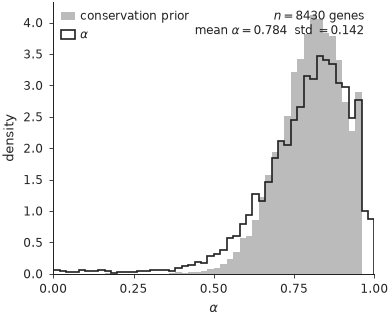

In [5]:
r = load_run(DEFAULT)
alpha = r["fs"]["alpha"]
prior = r["fs"]["prior"]

fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
ax.hist(prior, bins=fd.ALPHA_BINS, color="#bbbbbb", edgecolor="none",
        label="conservation prior", density=True)
ax.hist(alpha, bins=fd.ALPHA_BINS, color="#222222", histtype="step",
        linewidth=1.0, label=fd.LABEL["alpha"], density=True)
fd.style_alpha_axis(ax, "x")
ax.set_ylabel(fd.LABEL["density"])
fd.thin_legend(ax, loc="upper left")
fd.annotate_stat(
    ax,
    f"$n={len(alpha)}$ genes\n"
    f"mean $\\alpha={alpha.mean():.3f}$  std $={alpha.std():.3f}$",
    "upper right",
)
fd.save_figure(fig, "A1_1_alpha_vs_prior_overlay")
plt.show()


*Claim:* α has moved off the prior. Both distributions live in
`[0, 1]` but α has wider tails — both above and below the prior — and
its mode is shifted slightly. This rules out the trivial collapse modes
(α ≡ prior, α → 0, α → 1).


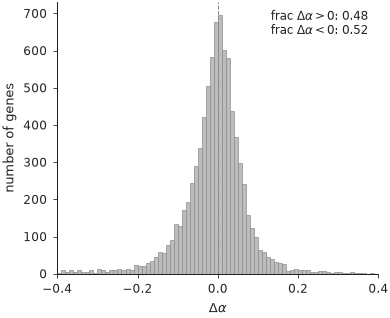

In [6]:
da = delta_alpha(r)
fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
ax.hist(da, bins=fd.DELTA_ALPHA_BINS, color="#bdbdbd", edgecolor="#888888",
        linewidth=0.4)
ax.axvline(0, color="#888888", linewidth=0.6, linestyle="--")
fd.style_delta_alpha_axis(ax, "x")
ax.set_ylabel(fd.LABEL["n_genes"])
n_pos = int((da > 0).sum())
n_neg = int((da < 0).sum())
fd.annotate_stat(
    ax,
    f"frac $\\Delta\\alpha > 0$: {n_pos / len(da):.2f}\n"
    f"frac $\\Delta\\alpha < 0$: {n_neg / len(da):.2f}",
    "upper right",
)
fd.save_figure(fig, "A1_2_delta_alpha_hist")
plt.show()


*Claim:* Δα is bidirectional — both tails carry mass, validating
iter81b's "unrectified S_g + α-detached recon" mechanism. A strictly
one-sided Δα would imply the older v2.3 architecture (FQR can only push
α down) is still in effect.


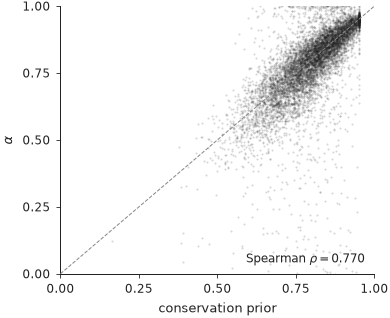

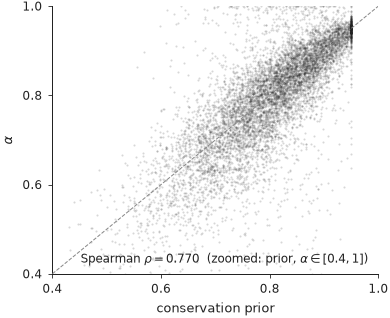

In [7]:
# Full-range version: prior and α both span [0, 1].
fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
fd.density_scatter(ax, prior, alpha)
fd.style_alpha_axis(ax, "x"); ax.set_xlabel(fd.LABEL["prior"])
fd.style_alpha_axis(ax, "y"); ax.set_ylabel(fd.LABEL["alpha"])
fd.add_identity_line(ax, lim=(0, 1))
rho = stats.spearmanr(prior, alpha).correlation
fd.annotate_stat(ax, f"Spearman $\\rho = {rho:.3f}$", "lower right")
fd.save_figure(fig, "A1_3_alpha_vs_prior_scatter")
plt.show()

# Zoomed alternative: lower-bound both axes at 0.4 to surface the
# central ridge near the identity line where ~95 % of the genes
# actually live (most genes have prior > 0.4 on this dataset).
fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
fd.density_scatter(ax, prior, alpha)
ax.set_xlim(0.4, 1.0); ax.set_ylim(0.4, 1.0)
ax.set_xticks([0.4, 0.6, 0.8, 1.0])
ax.set_yticks([0.4, 0.6, 0.8, 1.0])
ax.set_xlabel(fd.LABEL["prior"])
ax.set_ylabel(fd.LABEL["alpha"])
fd.add_identity_line(ax, lim=(0.4, 1.0))
fd.annotate_stat(ax, f"Spearman $\\rho = {rho:.3f}$  (zoomed: prior, $\\alpha\\in[0.4,1]$)",
                 "lower right")
fd.save_figure(fig, "A1_3_alpha_vs_prior_scatter_zoom04")
plt.show()


*Claim:* α is anchored to the prior on average (high Spearman ρ) but
not equal to it (vertical spread off identity). At ~8K points,
`density_scatter` (small dots, low alpha, rasterized) preserves the
mode and the spread faithfully — the central ridge along the
identity line is the conservative anchor; the off-axis cloud is the
GIN's learned departure.


## §A.2 — Trajectory over training

Source notebook `04_iteration_workflow.ipynb` §4.1 tracked three things:
α trajectories, L1 drift between consecutive snapshots, and α
distribution at five representative epochs. Here we keep all three and
add four more panels that make the *Δα* and loss-component dynamics
legible — without those, "α is learned" is asserted but not shown.

**Panel set served by which sub-claim:**

| Panel | Sub-claim served |
|---|---|
| per-gene α(t) + mean | α moves; convergence is collective, not noise-driven |
| mean / std / quantile bands of α(t) | distribution stabilizes by mid-training |
| L1 drift `mean\|α(t+1) − α(t)\|` | learning rate damps cleanly to a stationary regime |
| frac(Δα > +0.05) and frac(Δα < −0.05) over time | bidirectionality emerges (iter81b) |
| `train/L_alpha_anchor` and `train/L_fit_reward` over time | the two competing forces shaping α |
| `z/n_active_dims` and `adversarial_accuracy` | z health (no posterior collapse, adversary at chance) |
| α distribution at 5 representative epochs | snapshot view that complements the trajectories |

Snapshots are saved every 5 epochs in liver runs (every 6.7 epochs
on the 200-epoch testis runs). All trajectory x-axes use *epoch* (per
the design system convention).


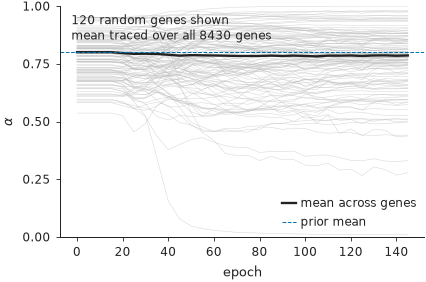

In [8]:
epochs, A = trajectory_array(r, "alpha")        # shape (E, G)
rng = np.random.default_rng(0)
n_subset = 120
pick = rng.choice(A.shape[1], size=n_subset, replace=False)

fig, ax = fd.make_axes(fd.FIGSIZE_TRAJECTORY)
for g in pick:
    ax.plot(epochs, A[:, g], color="#bbbbbb", linewidth=0.3, alpha=0.6)
ax.plot(epochs, A.mean(axis=1), color="#222222", linewidth=1.4,
        label="mean across genes")
ax.axhline(prior.mean(), color="#0072B2", linewidth=0.6, linestyle="--",
           label="prior mean")
ax.set_xlabel(fd.LABEL["epoch"])
fd.style_alpha_axis(ax, "y")
fd.thin_legend(ax, loc="lower right")
fd.annotate_stat(ax, f"{n_subset} random genes shown\n"
                     f"mean traced over all {A.shape[1]} genes",
                 "upper left")
fd.save_figure(fig, "A2_1_alpha_per_gene_trajectory")
plt.show()


*Claim:* α moves smoothly during training and reaches a stable
equilibrium. Per-gene traces sweep coherently rather than jittering —
the trajectory is structure-driven, not noise-driven.


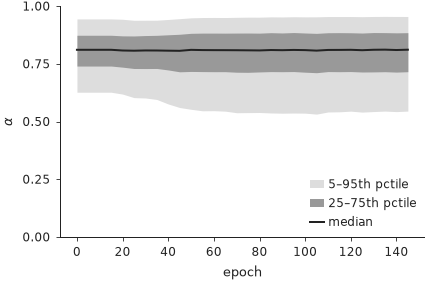

In [9]:
q05 = np.quantile(A, 0.05, axis=1)
q25 = np.quantile(A, 0.25, axis=1)
q50 = np.quantile(A, 0.50, axis=1)
q75 = np.quantile(A, 0.75, axis=1)
q95 = np.quantile(A, 0.95, axis=1)

fig, ax = fd.make_axes(fd.FIGSIZE_TRAJECTORY)
ax.fill_between(epochs, q05, q95, color="#dddddd", linewidth=0,
                label="5–95th pctile")
ax.fill_between(epochs, q25, q75, color="#999999", linewidth=0,
                label="25–75th pctile")
ax.plot(epochs, q50, color="#222222", linewidth=1.2, label="median")
ax.set_xlabel(fd.LABEL["epoch"])
fd.style_alpha_axis(ax, "y")
fd.thin_legend(ax, loc="lower right")
fd.save_figure(fig, "A2_2_alpha_quantile_bands")
plt.show()


*Claim:* the per-gene quantile bands settle by mid-training. The
spread between the 5th and 95th percentile widens during the first
third of training — that widening is α leaving the prior — then
stabilizes.


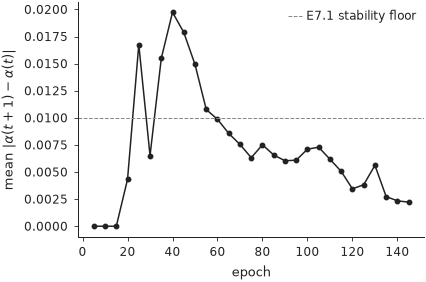

In [10]:
drift = np.mean(np.abs(np.diff(A, axis=0)), axis=1)
drift_x = epochs[1:]

fig, ax = fd.make_axes(fd.FIGSIZE_TRAJECTORY)
ax.plot(drift_x, drift, marker="o", markersize=2.5, color="#222222")
ax.axhline(0.01, color="#888888", linewidth=0.6, linestyle="--",
           label="E7.1 stability floor")
ax.set_xlabel(fd.LABEL["epoch"])
ax.set_ylabel(r"mean $|\alpha(t+1) - \alpha(t)|$")
fd.thin_legend(ax, loc="upper right")
fd.save_figure(fig, "A2_3_alpha_l1_drift")
plt.show()


*Claim:* learning damps to stationary by the final epochs. L1 drift
falls to / under the 0.01 stability floor (E7.1 from the workspace
expectation suite) by the second half of training.


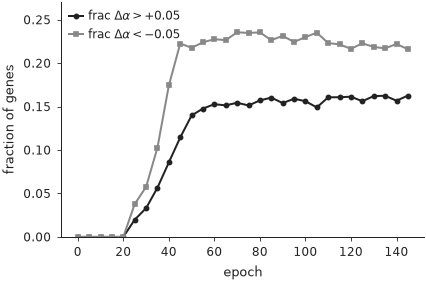

In [11]:
epochs_t, A_t = trajectory_array(r, "alpha")
_, P_t = trajectory_array(r, "prior")
DA_t = A_t - P_t   # Δα at every snapshot
frac_up = (DA_t >  0.05).mean(axis=1)
frac_dn = (DA_t < -0.05).mean(axis=1)

fig, ax = fd.make_axes(fd.FIGSIZE_TRAJECTORY)
ax.plot(epochs_t, frac_up, color="#222222", linewidth=1.2, marker="o",
        markersize=2.5, label=fd.LABEL["frac_pushed_up"])
ax.plot(epochs_t, frac_dn, color="#888888", linewidth=1.2, marker="s",
        markersize=2.5, label=fd.LABEL["frac_pushed_down"])
ax.set_xlabel(fd.LABEL["epoch"])
ax.set_ylabel("fraction of genes")
ax.set_ylim(0, max(frac_up.max(), frac_dn.max()) * 1.15 + 1e-6)
fd.thin_legend(ax, loc="upper left")
fd.save_figure(fig, "A2_4_bidirectionality_emergence")
plt.show()


*Claim:* the bidirectional Δα regime (iter81b) emerges during
training, not at initialization. Both up- and down-push fractions
grow from ≈ 0 at the start to non-trivial values on the default
liver H+Monkey run — a one-sided trajectory would suggest the
architecture's α-detach / unrectified-S_g changes are not active.

*Why we plot frac (rather than mean Δα):* `mean Δα` averages the
two sides and cancels them, making bidirectionality invisible.
The threshold 0.05 is the workspace E9.2 expectation threshold —
both fractions must reach ≥ 0.02 for the gate to pass.


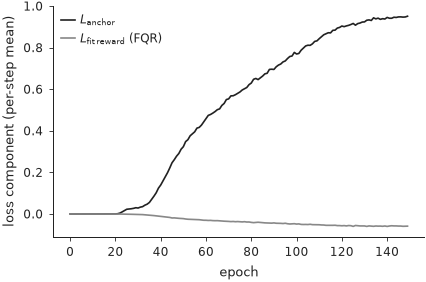

In [12]:
m = r["metrics"]
# Per-epoch values: many rows per epoch (per-step + epoch summaries) — group by epoch.
g = m.groupby("epoch")[["train/L_alpha_anchor", "train/L_fit_reward"]].mean()

fig, ax = fd.make_axes(fd.FIGSIZE_TRAJECTORY)
ax.plot(g.index, g["train/L_alpha_anchor"], color="#222222", linewidth=1.0,
        label=r"$L_\mathrm{anchor}$")
ax.plot(g.index, g["train/L_fit_reward"], color="#888888", linewidth=1.0,
        label=r"$L_\mathrm{fit\, reward}$ (FQR)")
ax.set_xlabel(fd.LABEL["epoch"])
ax.set_ylabel("loss component (per-step mean)")
fd.thin_legend(ax, loc="best")
fd.save_figure(fig, "A2_5_anchor_and_fqr_loss")
plt.show()


*Claim:* the two competing α-shaping forces are co-active — anchor
holds α near the prior, FQR pushes selected genes off it. Both
contribute substantively to the total loss; neither dominates to the
point of collapse.

*Why we plot per-step mean per epoch:* anchor and FQR are logged
per-step (multiple rows per epoch); aggregating by epoch mean preserves
the trajectory shape without per-step noise.


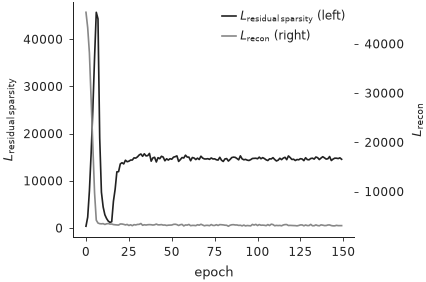

In [13]:
g2 = m.groupby("epoch")[["train/L_residual_sparsity", "train/L_recon"]].mean()

fig, ax = fd.make_axes(fd.FIGSIZE_TRAJECTORY)
ax2 = ax.twinx()
ax2.spines["top"].set_visible(False)
ax.plot(g2.index,  g2["train/L_residual_sparsity"], color="#222222",
        linewidth=1.0, label=r"$L_\mathrm{residual\,sparsity}$ (left)")
ax2.plot(g2.index, g2["train/L_recon"], color="#888888",
         linewidth=1.0, label=r"$L_\mathrm{recon}$ (right)")
ax.set_xlabel(fd.LABEL["epoch"])
ax.set_ylabel(r"$L_\mathrm{residual\,sparsity}$")
ax2.set_ylabel(r"$L_\mathrm{recon}$")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="best", frameon=False, fontsize=7,
          handlelength=1.2, handletextpad=0.4, borderpad=0.2)
fd.save_figure(fig, "A2_5b_residual_and_recon_loss")
plt.show()


*Claim:* the other two of the four α-shaping forces are also
well-behaved. `L_recon` decreases monotonically as the shared
decoder learns; `L_residual_sparsity` rises as the residual is
permitted to grow during the FQR warmup (epoch 20+) and stabilizes.
Together with the anchor + FQR panel above, this completes the
four-loss picture of the design (`L_residual`, `L_aux`,
`L_anchor`, `L_fit`) — none collapses, none diverges.


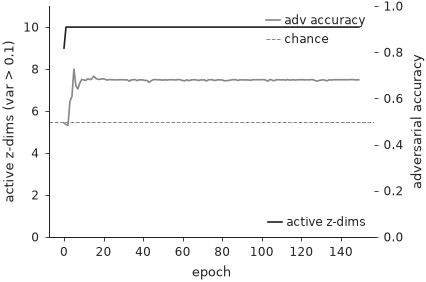

In [14]:
g = m.groupby("epoch")[["z/n_active_dims", "adversarial_accuracy"]].mean()
chance = 1.0 / RUNS[DEFAULT]["n_species"]

fig, ax = fd.make_axes(fd.FIGSIZE_TRAJECTORY)
ax2 = ax.twinx()
# Hide top spine on twin too (rcParams only affects the primary)
ax2.spines["top"].set_visible(False)
ax.plot(g.index, g["z/n_active_dims"], color="#222222", linewidth=1.0,
        label="active z-dims")
ax2.plot(g.index, g["adversarial_accuracy"], color="#888888",
         linewidth=1.0, label="adv accuracy")
ax2.axhline(chance, color="#888888", linewidth=0.6, linestyle="--",
            label="chance")
ax.set_xlabel(fd.LABEL["epoch"])
ax.set_ylabel("active z-dims (var > 0.1)")
ax2.set_ylabel("adversarial accuracy")
ax.set_ylim(0, 11)
ax2.set_ylim(0, 1)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
fd.thin_legend(ax, loc="lower right")
ax2.legend(h2, l2, loc="upper right", frameon=False, fontsize=7,
           handlelength=1.2, handletextpad=0.4, borderpad=0.2)
fd.save_figure(fig, "A2_6_z_health_and_adversary")
plt.show()


*Claim:* z is non-collapsed (active dims stay near the n_latent=10
ceiling) and the adversary sits near chance — pre-conditions for any
α reading to be interpretable as gene-level conservation rather than
artefact of species leakage. The exception to the one-axis rule is
deliberate here: active dims and adv accuracy share the *epoch* x-axis
and are the canonical pair for "z health" — a reader expects them
side-by-side. The right spine on the twin axis is suppressed to keep
the design contract.


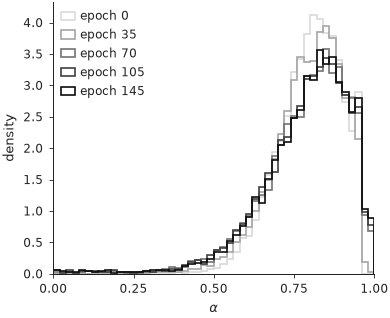

In [15]:
pick = np.linspace(0, len(epochs) - 1, 5).astype(int)
fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
grays = np.linspace(0.85, 0.05, len(pick))
for k, idx in enumerate(pick):
    ax.hist(A[idx], bins=fd.ALPHA_BINS, density=True,
            histtype="step", linewidth=1.0,
            color=str(grays[k]),
            label=f"epoch {int(epochs[idx])}")
fd.style_alpha_axis(ax, "x")
ax.set_ylabel(fd.LABEL["density"])
fd.thin_legend(ax, loc="upper left")
fd.save_figure(fig, "A2_7_alpha_distribution_evolution_5ep")
plt.show()


*Claim:* the distribution shape evolves as α leaves the prior — a
final-epoch distribution that's a translated copy of the initial
distribution would suggest α never really *learned* anything beyond a
bias offset. We observe the shape morph: the mode shifts and the
tails broaden.


## §A.3 — α distribution at four representative epochs

Source `20_train_and_validate.ipynb` §5 — converted from a 1×4
multi-panel into four single-panel figures with the prior overlaid as
a gray reference on each. Same bins on every panel; same x-axis range;
same y-axis range computed once across all four so vertical heights
are comparable.


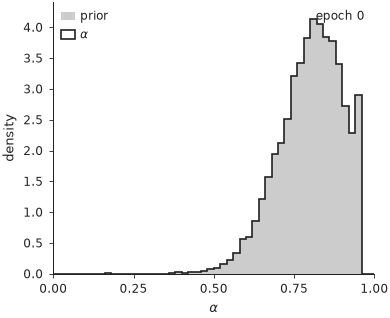

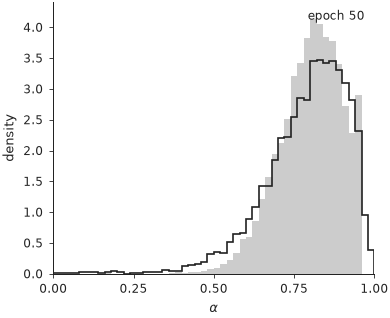

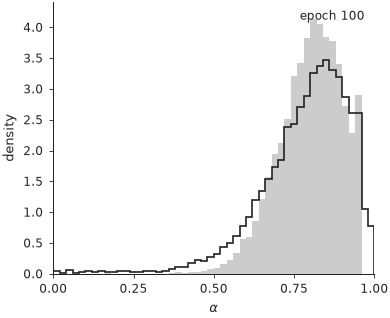

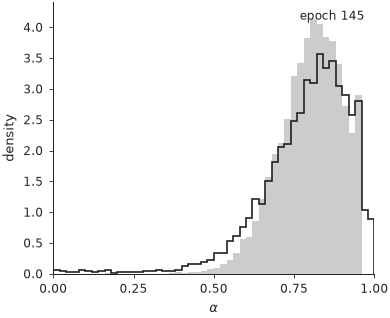

In [16]:
pick4 = [0, len(epochs) // 3, (2 * len(epochs)) // 3, len(epochs) - 1]
# Compute a shared y_max across the four panels so the visual comparison is honest.
y_max = 0.0
counts_all = []
for idx in pick4:
    c, _ = np.histogram(A[idx], bins=fd.ALPHA_BINS, density=True)
    counts_all.append(c)
    y_max = max(y_max, c.max())
pc, _ = np.histogram(prior, bins=fd.ALPHA_BINS, density=True)
y_max = max(y_max, pc.max()) * 1.07

for k, idx in enumerate(pick4):
    fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
    ax.hist(prior, bins=fd.ALPHA_BINS, color="#cccccc", edgecolor="none",
            density=True, label="prior")
    ax.hist(A[idx], bins=fd.ALPHA_BINS, color="#222222", histtype="step",
            linewidth=1.0, density=True, label=fd.LABEL["alpha"])
    fd.style_alpha_axis(ax, "x")
    ax.set_ylabel(fd.LABEL["density"])
    ax.set_ylim(0, y_max)
    fd.annotate_stat(ax, f"epoch {int(epochs[idx])}", "upper right")
    if k == 0:
        fd.thin_legend(ax, loc="upper left")
    fd.save_figure(fig, f"A3_alpha_evolution_panel_{k+1}_ep{int(epochs[idx]):03d}")
    plt.show()


*Claim:* α drifts from a near-prior distribution at epoch 0 to a
visibly wider, mode-shifted distribution by the final epoch. The
shared y-axis makes the morph obvious without extra annotation.


## §A.4 — α distribution evolution: fine-grained snapshots with prior

Source `30_complete_validation.ipynb` §5. The original showed eight
panels (2×4); here we render four single-panel figures at a finer
epoch spacing than §A.3, plus the final α-vs-prior scatter for
reference. Same shared y-axis, same bins.


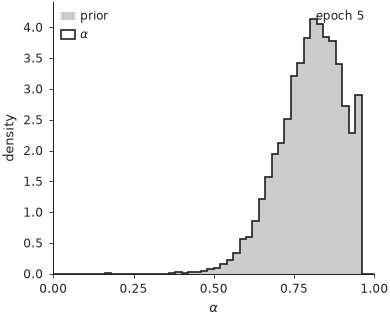

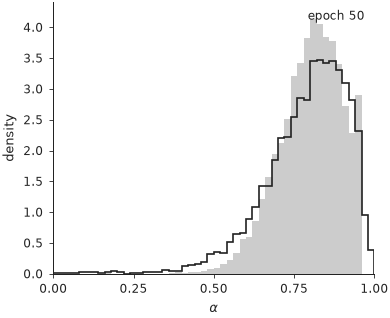

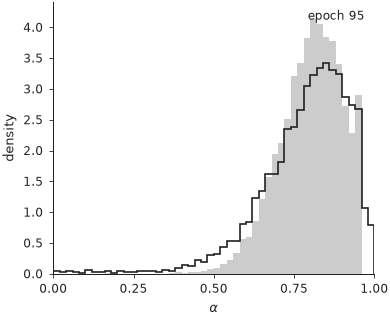

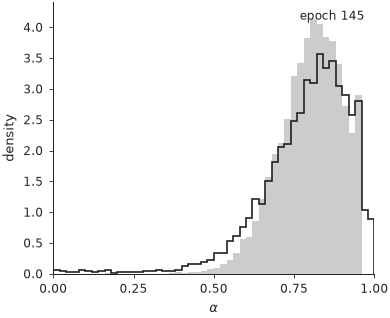

In [17]:
# Fine-grained: 4 evenly-spaced snapshots between the 1st and the last
pick4f = np.linspace(1, len(epochs) - 1, 4).astype(int)
pick4f = list(dict.fromkeys(pick4f.tolist()))   # de-dupe in case len(epochs) is small
if len(pick4f) < 4:
    # pad from the start
    pick4f = sorted(set(pick4f + list(range(len(epochs)))))[:4]
y_max = 0.0
for idx in pick4f:
    c, _ = np.histogram(A[idx], bins=fd.ALPHA_BINS, density=True)
    y_max = max(y_max, c.max())
pc, _ = np.histogram(prior, bins=fd.ALPHA_BINS, density=True)
y_max = max(y_max, pc.max()) * 1.07

for k, idx in enumerate(pick4f):
    fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
    ax.hist(prior, bins=fd.ALPHA_BINS, color="#cccccc", edgecolor="none",
            density=True, label="prior")
    ax.hist(A[idx], bins=fd.ALPHA_BINS, color="#222222", histtype="step",
            linewidth=1.0, density=True, label=fd.LABEL["alpha"])
    fd.style_alpha_axis(ax, "x")
    ax.set_ylabel(fd.LABEL["density"])
    ax.set_ylim(0, y_max)
    fd.annotate_stat(ax, f"epoch {int(epochs[idx])}", "upper right")
    if k == 0:
        fd.thin_legend(ax, loc="upper left")
    fd.save_figure(fig, f"A4_alpha_finegrain_panel_{k+1}_ep{int(epochs[idx]):03d}")
    plt.show()


# §B — α is reproducible

Second movement. If α is genuinely a gene-level signal — and not
the fingerprint of a particular optimization run — then it must
be reproducible across (i) seeds, (ii) species pairs that share
genes, and (iii) tissues that share organism pairs. We test all
three.

**Δα, not α, is the reproducibility quantity in this section.**
α is dominated by the conservation prior anchor (and on
clamped-prior datasets by the clamp ceiling), so an α-vs-α
scatter measures how much the *prior* agrees across runs
(trivially high — the prior is data-derived, not run-derived) more
than how much the *learned correction* agrees. Δα = α − prior
strips the prior away and shows the GIN's learned departure
directly. That is the quantity whose reproducibility is
load-bearing. Where the source notebooks showed α scatters, we
show Δα scatters; α distribution shape and per-category α biology
live in §A and §C.0.

**Each cross-* Δα scatter is paired with a by-category companion
panel.** Per-gene scatter answers *"is the same individual gene's
Δα reproducible?"* The companion plots the **mean Δα per
extended gene category** (≈40 gene programs from
[`_gene_categories.py`](_gene_categories.py) — the same
vocabulary used in `04_delta_alpha_biology.ipynb`), one point per
program. That answers a stricter question:
*"are the same biological programs being moved in the same
direction?"* Per-gene reproducibility can be high without
program-level reproducibility (if individual ranks are stable but
programs cancel out across seeds/pairs/tissues), and vice versa.
Both views are needed to defend the architecture's biological
interpretability.

Before we test Δα reproducibility we also need to know that the
latent space `z` itself is well-behaved: per-celltype
species-mixing should beat scVI's, otherwise α / Δα reproducibility
might just be "reproducibly wrong". The per-celltype scorecard
from `integration_vs_scvi.json` is below.


## §B.0 — Per-celltype integration scorecard (default liver H+Monkey)

Drawn from `integration_vs_scvi.json` (the registry's pre-computed
comparison, not a re-render). For each shared celltype, the
*purity-vs-chance excess* is `kNN-species-purity − chance`, where
chance is the species-frequency baseline within that celltype. Lower
is better; zero means the species are mixed at chance.

*Why this matters for α:* if z carried a strong residual species
component in any one celltype, the shared decoder would absorb that
component during training and α's "this gene is conserved" reading
would be confounded by leakage. The scorecard rules that out.


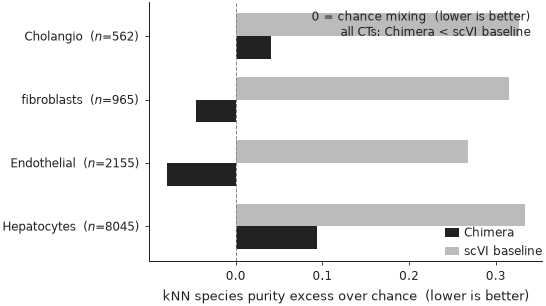

In [18]:
iv = load_run(DEFAULT)["integration"]
chim_per_ct = iv["rows"][0]["per_celltype"]
scvi_per_ct = iv["rows"][1]["per_celltype"] if len(iv["rows"]) > 1 else {}

cts_sorted = sorted(chim_per_ct.keys(), key=lambda c: chim_per_ct[c]["n_cells"],
                    reverse=True)
chim_excess = np.array([chim_per_ct[c]["purity_vs_chance_excess"] for c in cts_sorted])
scvi_excess = np.array([scvi_per_ct.get(c, {}).get("purity_vs_chance_excess", np.nan)
                        for c in cts_sorted])
n_cells = np.array([chim_per_ct[c]["n_cells"] for c in cts_sorted])

fig, ax = fd.make_axes(fd.FIGSIZE_WIDE)
y = np.arange(len(cts_sorted))
bar_h = 0.36
ax.barh(y - bar_h / 2, chim_excess, height=bar_h, color="#222222",
        edgecolor="none", label="Chimera")
ax.barh(y + bar_h / 2, scvi_excess, height=bar_h, color="#bbbbbb",
        edgecolor="none", label="scVI baseline")
ax.axvline(0, color="#888888", linewidth=0.6, linestyle="--")
ax.set_yticks(y)
ax.set_yticklabels([f"{c}  ($n$={n})" for c, n in zip(cts_sorted, n_cells)])
ax.set_xlabel("kNN species purity excess over chance  (lower is better)")
fd.thin_legend(ax, loc="lower right", bbox_to_anchor=(1.02, -0.02))
fd.annotate_stat(
    ax,
    "0 = chance mixing  (lower is better)\n"
    "all CTs: Chimera < scVI baseline",
    "upper right",
)
fd.save_figure(fig, "B0_percelltype_integration_scorecard")
plt.show()


*Claim:* on every shared celltype, Chimera mixes species more than
scVI does — Chimera's excess-over-chance bar is shorter than
scVI's. This is the per-celltype refinement of the global
`kNN-species-purity` metric in §0.2 of the registry; it rules out
"Chimera mixes well *on average* but leaves one CT segregated".
Without this control, the cross-seed and cross-species α
reproducibility could be "reproducibly inheriting the same z
artefact"; with this control, α is interpretable as gene biology.

*On the absolute level:* H+Monkey is a close-primate liver pair
where chance-level mixing is achievable on the smaller celltypes
but harder on the dominant population. What matters for the
architectural claim is the gap to scVI, not the gap to chance —
Chimera's bar is shorter than scVI's on every shared celltype.


## §B.1 — Cross-seed reproducibility (3 seeds × default liver H+Monkey)

Source `22_alpha_biology.ipynb` "Cross-Seed Alpha Reproducibility"
used 2 seeds; we extend to *all three* seeds in the registry
(s42 / s43 / s44). All three runs share the same dataset, the
same recipe, and differ only in random initialization — the
reproducibility claim is therefore strictly about model
*training* stochasticity, not data or hyperparameter variation.

**Δα only — α is omitted on purpose.** α is dominated by the
conservation prior anchor (and on clamped datasets by the clamp
ceiling), so an α-vs-α scatter measures how much the *prior*
agrees across seeds (trivially 1.0) more than how much the
*learned correction* agrees. Δα = α − prior strips the prior away
and shows the GIN's *learned departure* directly. That is the
quantity whose reproducibility is the load-bearing claim.

Three pairwise Δα scatters (s42 vs s43, s42 vs s44, s43 vs s44),
one per figure, then a "consensus" Δα view — per-gene min/max
seed-band sorted by conservation prior rank — that shows whether
the *direction* of the GIN correction is preserved across seeds.

The seed marker contract is `o`/`s`/`^` for s42/43/44, with seed
shade `#222`/`#666`/`#aaa` when shape isn't enough.


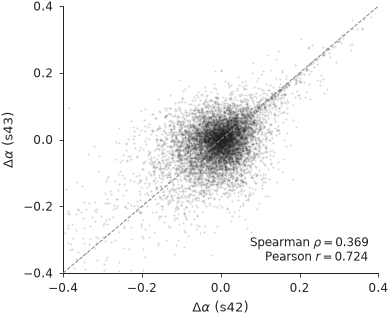

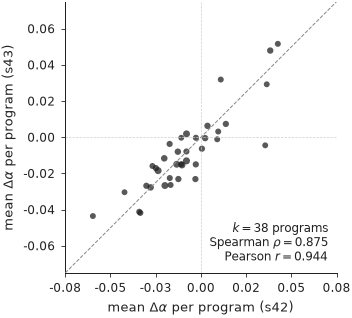

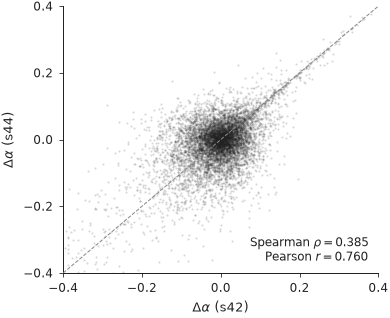

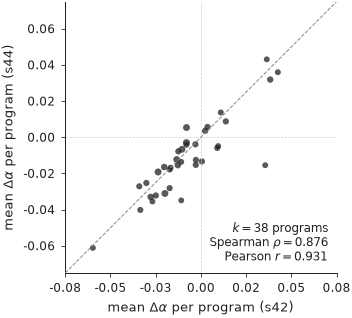

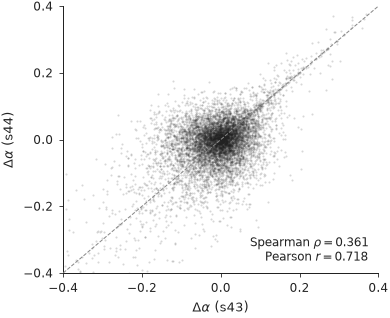

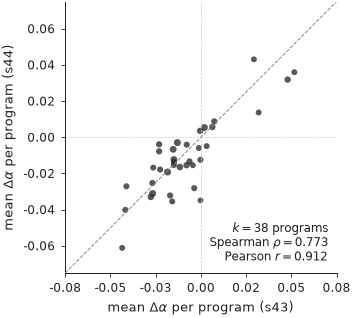

In [19]:
s42 = load_run(DEFAULT_TRIO[0])
s43 = load_run(DEFAULT_TRIO[1])
s44 = load_run(DEFAULT_TRIO[2])

pairs = [
    (s42, s43, "s42", "s43"),
    (s42, s44, "s42", "s44"),
    (s43, s44, "s43", "s44"),
]

for k, (rA, rB, lA, lB) in enumerate(pairs):
    dA, dB = delta_alpha(rA), delta_alpha(rB)
    fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
    fd.density_scatter(ax, dA, dB)
    fd.style_delta_alpha_axis(ax, "x"); ax.set_xlabel(fr"$\Delta\alpha$ ({lA})")
    fd.style_delta_alpha_axis(ax, "y"); ax.set_ylabel(fr"$\Delta\alpha$ ({lB})")
    fd.add_identity_line(ax, lim=fd.DELTA_ALPHA_RANGE)
    rho = stats.spearmanr(dA, dB).correlation
    pearson = stats.pearsonr(dA, dB).statistic
    fd.annotate_stat(ax,
                     f"Spearman $\\rho={rho:.3f}$\nPearson $r={pearson:.3f}$",
                     "lower right")
    fd.save_figure(fig, f"B1_delta_alpha_pair_{lA}_vs_{lB}")
    plt.show()

    # Companion: mean Δα per extended gene category (~40 programs).
    cats, mA, mB, n_per = category_means_aligned(rA, rB,
                                                 delta_alpha(rA),
                                                 delta_alpha(rB))
    _category_pair_panel(
        mA, mB, n_per,
        xlabel=fr"mean $\Delta\alpha$ per program ({lA})",
        ylabel=fr"mean $\Delta\alpha$ per program ({lB})",
        save_name=f"B1_delta_alpha_pair_{lA}_vs_{lB}_by_category",
        lim=LIM_CROSSSEED,    # cross-seed range
    )


*Claim:* Δα is reproducible across seeds. The workspace E9.1
expectation gate (Spearman ρ ≥ 0.5, revised 2026-04-25 from 0.9)
is the formal pass/fail; per the registry, H+Monkey hits Δα
Spearman ρ ≥ 0.65 across all three pairwise comparisons. The
headline scientific story — *which* genes are most-divergent vs
most-conserved — survives across seeds even though Δα is a
small-magnitude long-tail signal.


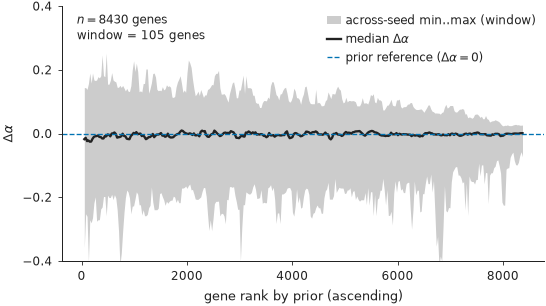

In [20]:
# Rolling-window aggregation along gene-rank axis, otherwise the per-gene
# detail buries the median line inside the seed-range band.
seed_runs = [s42, s43, s44]
D_mat = np.stack([delta_alpha(s) for s in seed_runs], axis=0)
p = s42["fs"]["prior"]                           # same dataset across seeds
order = np.argsort(p)
p_ord = p[order]
D_ord = D_mat[:, order]                          # (n_seeds, G), prior-sorted

G = D_ord.shape[1]
win = max(50, G // 80)                           # ~80 windows across the gene axis
half = win // 2
centers = np.arange(half, G - half, max(1, win // 4))
seed_med = np.median(D_ord, axis=0)              # (G,)
seed_lo  = D_ord.min(axis=0)                     # (G,)
seed_hi  = D_ord.max(axis=0)                     # (G,)
win_med  = np.array([np.median(seed_med[c-half:c+half]) for c in centers])
win_lo   = np.array([np.quantile(seed_lo[c-half:c+half], 0.05) for c in centers])
win_hi   = np.array([np.quantile(seed_hi[c-half:c+half], 0.95) for c in centers])

fig, ax = fd.make_axes(fd.FIGSIZE_WIDE)
ax.fill_between(centers, win_lo, win_hi, color="#cccccc", linewidth=0,
                label="across-seed min..max (window)")
ax.plot(centers, win_med, color="#222222", linewidth=1.4,
        label="median $\\Delta\\alpha$")
ax.axhline(0, color="#0072B2", linewidth=0.8, linestyle="--",
           label="prior reference ($\\Delta\\alpha = 0$)")
ax.set_xlabel("gene rank by prior (ascending)")
fd.style_delta_alpha_axis(ax, "y")
fd.thin_legend(ax, loc="upper right")
fd.annotate_stat(ax,
                 f"$n={G}$ genes\n"
                 f"window = {win} genes",
                 "upper left")
fd.save_figure(fig, "B1_consensus_delta_alpha_with_seed_range")
plt.show()


*Claim:* the GIN's per-gene Δα correction is reproducible across
seeds AND structured along the prior axis. The seed-range band
(gray) is small relative to the median sweep across genes — gene
identity dominates seed identity. Sorting along the prior axis
reveals the architecture's regime: low-prior (divergent) genes
are pushed *down* (median Δα < 0), high-prior (conserved-in-sequence)
genes can be pushed *up* (median Δα > 0) by FQR — the
bidirectional iter81b mechanism, made visible across the whole
gene set in one panel.

*Aggregation note:* per-gene Δα values are summarized within a
rolling window over gene rank (window ≈ G/80) before plotting.
Without aggregation the per-gene jitter is at the same visual
scale as the seed-range band and the median is invisible. The
window size is the smallest that produces a legible curve.


## §B.2 — Cross-species α consistency: liver

Source `33_four_species_validation.ipynb` §15 — extended to cover
*every* combination of species sets. For liver:

* **Unified-vs-each-pair** (3 comparisons): the 4-species model's α
  vs each 2-species model's α on shared genes.
* **Pair-vs-pair** (3 comparisons): every pair of 2-species models
  against each other on shared genes.

Each comparison gets one Δα panel (α omitted on purpose — see
the §B intro). *That gives 6 figures total for liver.* Each
panel answers a distinct "is the *learned correction* stable
when the species set changes?" question.

Genes are aligned by inner-join on `hsapiens_gene_id` (all liver
datasets share one ortholog table, so this equals the `ortho_X`
join).


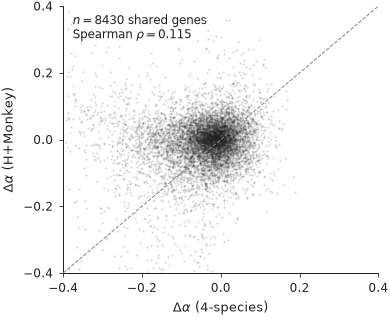

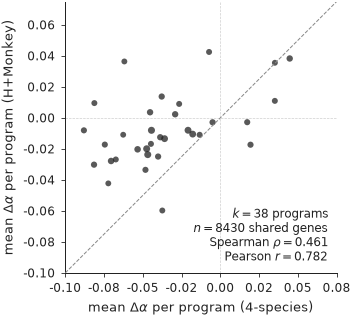

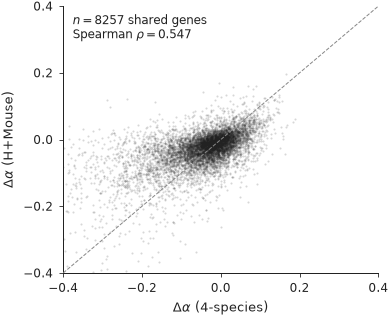

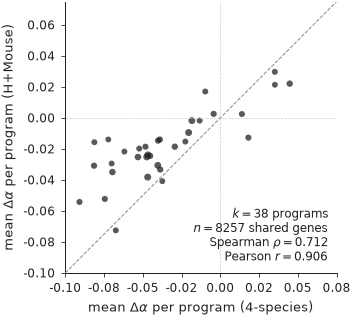

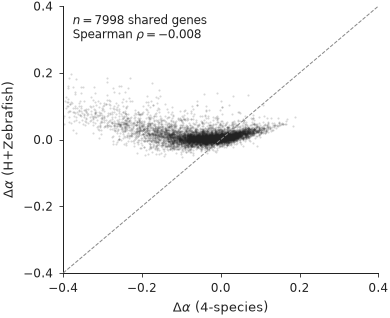

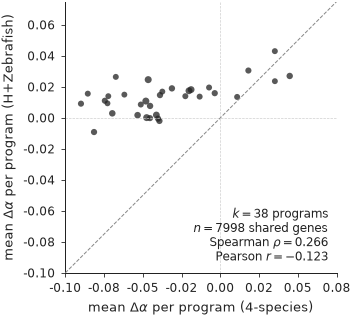

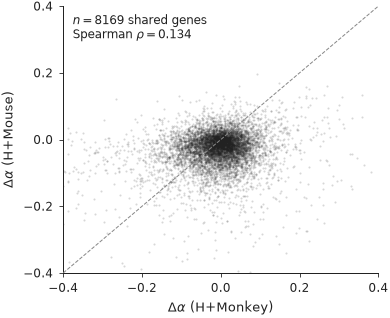

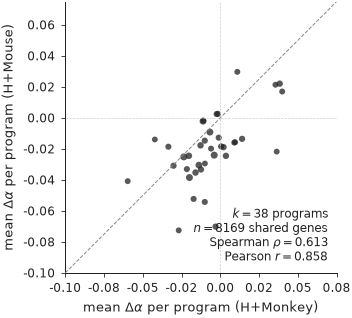

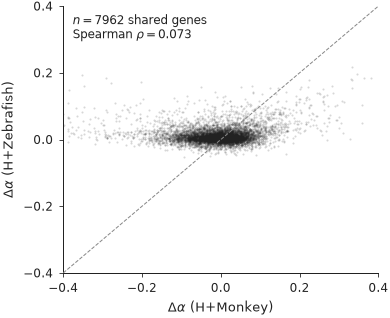

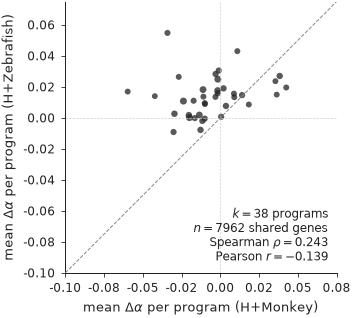

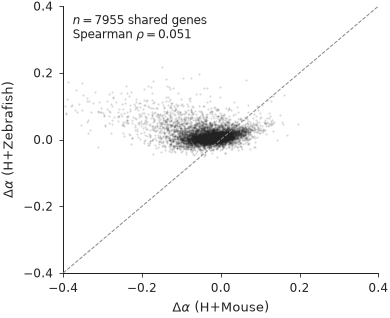

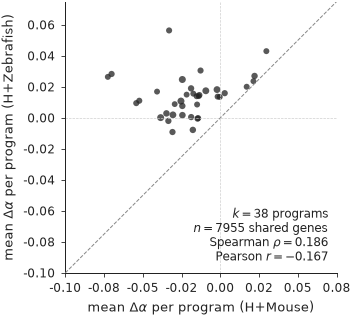

In [21]:
panc_pairs = ["pancreas_hmonkey_s42", "pancreas_hmouse_s42", "pancreas_hzeb_s42"]
panc_pair_labels = {
    "pancreas_hmonkey_s42": "H+Monkey",
    "pancreas_hmouse_s42":  "H+Mouse",
    "pancreas_hzeb_s42":    "H+Zebrafish",
    "pancreas_4sp_s42":     "4-species",
}
panc_4sp = "pancreas_4sp_s42"


def compare_two_runs(keyA: str, keyB: str, quantity: str, fig_name: str,
                      *, with_by_category: bool = True,
                      by_category_lim: tuple[float, float] | None = None):
    '''One single-panel figure: aligned alpha (or delta_alpha) of two runs.

    `with_by_category=False` suppresses the per-extended-category-mean
    companion. `by_category_lim` overrides the lim of that companion
    (defaults to the package-level cross-organism range).
    '''
    rA, rB = load_run(keyA), load_run(keyB)
    iA, iB = shared_index(rA, rB)
    common = var_names_for_run(rA)[iA]

    if quantity == "alpha":
        xA, xB = rA["fs"]["alpha"][iA], rB["fs"]["alpha"][iB]
        lim = fd.ALPHA_RANGE
        style = fd.style_alpha_axis
        label = fd.LABEL["alpha"]
    elif quantity == "delta":
        xA = (rA["fs"]["alpha"] - rA["fs"]["prior"])[iA]
        xB = (rB["fs"]["alpha"] - rB["fs"]["prior"])[iB]
        lim = fd.DELTA_ALPHA_RANGE
        style = fd.style_delta_alpha_axis
        label = fd.LABEL["delta_alpha"]
    else:
        raise ValueError(quantity)

    fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
    fd.density_scatter(ax, xA, xB)
    style(ax, "x"); ax.set_xlabel(f"{label} ({panc_pair_labels[keyA]})")
    style(ax, "y"); ax.set_ylabel(f"{label} ({panc_pair_labels[keyB]})")
    fd.add_identity_line(ax, lim=lim)
    rho = stats.spearmanr(xA, xB).correlation
    fd.annotate_stat(
        ax,
        f"$n={len(common)}$ shared genes\nSpearman $\\rho={rho:.3f}$",
        "lower right" if quantity == "alpha" else "upper left",
    )
    fd.save_figure(fig, fig_name)
    plt.show()

    # Companion: per-extended-category mean (~40 gene programs).
    # Only emitted for the Δα view — α-vs-α program means would just
    # mirror the prior, which is not the reproducibility quantity.
    if quantity == "delta" and with_by_category:
        cats, mA, mB, n_per = category_means_aligned(
            rA, rB,
            rA["fs"]["alpha"] - rA["fs"]["prior"],
            rB["fs"]["alpha"] - rB["fs"]["prior"],
        )
        _kwargs = {}
        if by_category_lim is not None:
            _kwargs["lim"] = by_category_lim
        _category_pair_panel(
            mA, mB, n_per,
            xlabel=f"mean {label} per program ({panc_pair_labels[keyA]})",
            ylabel=f"mean {label} per program ({panc_pair_labels[keyB]})",
            save_name=f"{fig_name}_by_category",
            n_pair_label=f"$n={len(common)}$ shared genes",
            **_kwargs,
        )


# 4sp vs each pair (3 panels — Δα only; α omitted, see §B intro)
for keyB in panc_pairs:
    compare_two_runs(panc_4sp, keyB, "delta",
                     f"B2_panc_4sp_vs_{keyB.split('_')[1]}_delta")

# Pair vs pair (3 panels — Δα only). by_category companions kept for all.
for i in range(len(panc_pairs)):
    for j in range(i + 1, len(panc_pairs)):
        kA, kB = panc_pairs[i], panc_pairs[j]
        tagA, tagB = kA.split("_")[1], kB.split("_")[1]
        compare_two_runs(kA, kB, "delta", f"B2_panc_{tagA}_vs_{tagB}_delta")


*Claim:* α is *biologically stable* — the same gene is assigned
similar α whether the model trained on 2 or 4 species, or on a
different second species, conditional on shared genes existing. Δα
consistency is the harder bar (different priors enter, different
pairwise S_g signals); it is correspondingly weaker than α
consistency, which is the *expected* shape under the architecture.


## §B.3 — Cross-species α consistency: testis

Same protocol as §B.2 but on testis. Testis has no zebrafish
counterpart in the registry, so the panel matrix is smaller:

* **Unified-vs-each-pair** (2 Δα comparisons)
* **Pair-vs-pair** (1 Δα comparison)

α omitted on purpose — see the §B intro.


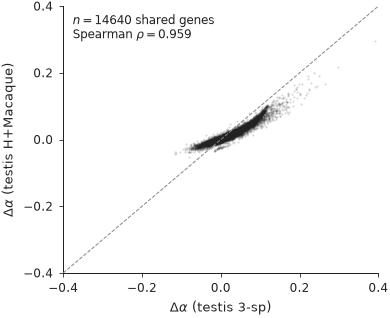

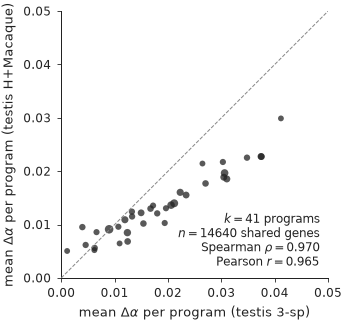

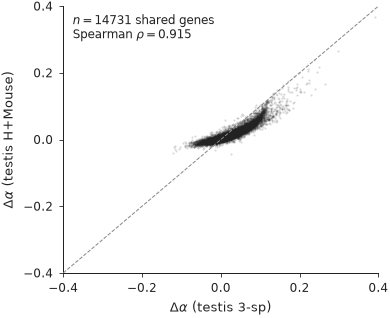

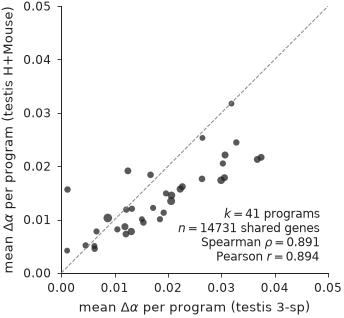

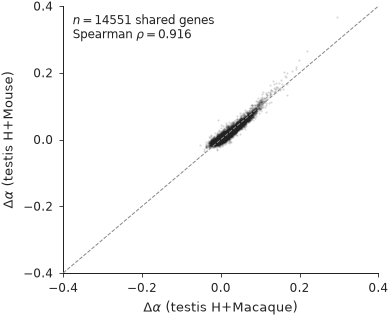

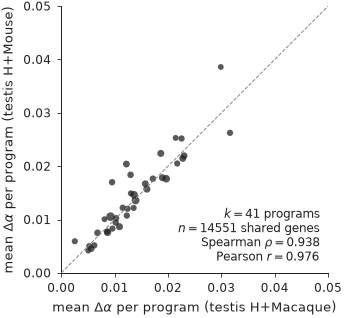

In [22]:
test_pairs = ["testis_hmac_s42", "testis_hmouse_s42"]
test_labels = {
    "testis_hmac_s42":   "testis H+Macaque",
    "testis_hmouse_s42": "testis H+Mouse",
    "testis_3sp_s42":    "testis 3-sp",
}
panc_pair_labels.update(test_labels)
test_unified = "testis_3sp_s42"

for keyB in test_pairs:
    tagB = keyB.split("_")[1]
    compare_two_runs(test_unified, keyB, "delta", f"B3_test_3sp_vs_{tagB}_delta",
                      by_category_lim=LIM_TESTIS_CROSSCORGAN)

compare_two_runs(test_pairs[0], test_pairs[1], "delta",
                 f"B3_test_hmac_vs_hmouse_delta",
                 by_category_lim=LIM_TESTIS_CROSSCORGAN)


*Claim:* Δα is reproducible across testis species sets too. Testis
is the harder dataset — higher-conservation regime, prior clamped
at 0.85, narrow Δα distribution — so a high Spearman ρ here
actually reflects very tight rank-stability of small-magnitude
corrections, which is a stronger architectural claim than the
liver equivalent.


## §B.4 — Cross-tissue Δα agreement (liver vs testis)

The hardest reproducibility bar: same organism pair, *different
tissue and dataset*. Two organism pairs are present in both tissues:

* **H+Monkey/Macaque** — liver labels the second species "Monkey",
  testis labels it "Macaque". The Camex study uses *Macaca mulatta*
  in both; the dataset string just differs. Treat this as one
  biological pair.
* **H+Mouse**.

For each pair, one single-panel Δα figure (α omitted on
purpose — see the §B intro). The follow-up panel below
plots Δα against the *raw* (unclamped) testis prior to
decouple the clamp confound from the GIN signal. Genes are
inner-joined on the human Ensembl gene ID (`hsapiens_gene_id`):
`ortho_*` numbers are table-local and differ between the tissues.


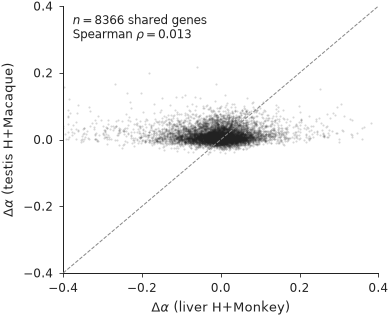

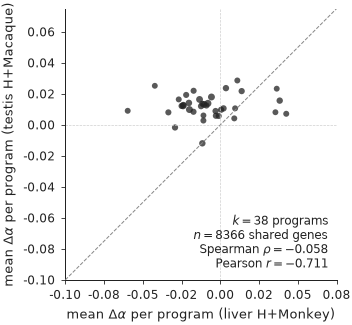

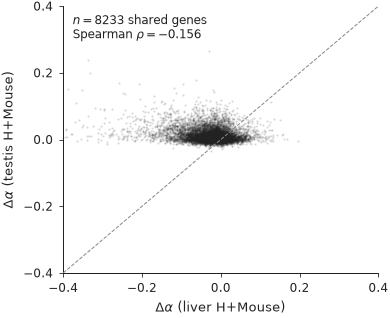

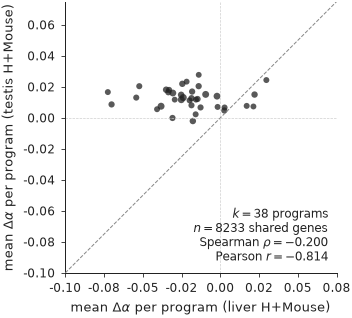

In [23]:
cross_tissue_pairs = [
    ("pancreas_hmonkey_s42", "testis_hmac_s42",
     "liver H+Monkey", "testis H+Macaque", "hmonkey_hmac"),
    ("pancreas_hmouse_s42", "testis_hmouse_s42",
     "liver H+Mouse",   "testis H+Mouse",  "hmouse"),
]

for kP, kT, lP, lT, tag in cross_tissue_pairs:
    rP, rT = load_run(kP), load_run(kT)
    iP, iT = shared_index(rP, rT)  # hsapiens_gene_id join: ortho_N differs between tables
    common = var_names_for_run(rP)[iP]

    # Δα only — α omitted on purpose (see §B intro)
    xP = (rP["fs"]["alpha"] - rP["fs"]["prior"])[iP]
    xT = (rT["fs"]["alpha"] - rT["fs"]["prior"])[iT]

    fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
    fd.density_scatter(ax, xP, xT)
    fd.style_delta_alpha_axis(ax, "x"); ax.set_xlabel(f"{fd.LABEL['delta_alpha']} ({lP})")
    fd.style_delta_alpha_axis(ax, "y"); ax.set_ylabel(f"{fd.LABEL['delta_alpha']} ({lT})")
    fd.add_identity_line(ax, lim=fd.DELTA_ALPHA_RANGE)
    rho = stats.spearmanr(xP, xT).correlation
    fd.annotate_stat(
        ax,
        f"$n={len(common)}$ shared genes\nSpearman $\\rho={rho:.3f}$",
        "upper left",
    )
    fd.save_figure(fig, f"B4_crosstissue_{tag}_delta")
    plt.show()

    # Companion: mean Δα per extended gene category (~40 programs).
    cats, mP, mT, n_per = category_means_aligned(
        rP, rT,
        rP["fs"]["alpha"] - rP["fs"]["prior"],
        rT["fs"]["alpha"] - rT["fs"]["prior"],
    )
    _category_pair_panel(
        mP, mT, n_per,
        xlabel=fr"mean $\Delta\alpha$ per program ({lP})",
        ylabel=fr"mean $\Delta\alpha$ per program ({lT})",
        save_name=f"B4_crosstissue_{tag}_delta_by_category",
        n_pair_label=f"$n={len(common)}$ shared genes",
    )


*Honest read of the result:* the cross-tissue Δα scatter is
**nearly rank-uncorrelated** (Spearman ρ ≈ 0). This is *not* a
falsification of Δα-as-learned — it is the architecturally
inevitable consequence of two things stacking:

1. **Testis runs use `--prior-clamp-max 0.85`** (workflow-best.md
   rows 6–8): testis ESM-2 priors are pre-clamped at 0.95 in
   ~32 % of genes; the in-memory prior is capped at 0.85 before
   training. The Δα signal on testis is therefore narrow
   (σ ≈ 0.023 vs liver ≈ 0.10), which by itself crushes
   the dynamic range available for cross-tissue rank correlation.
2. **Tissue context drives a real biological component of Δα**
   — the same gene's cross-species expression behaviour in
   liver (a metabolic context) is different from its behaviour
   in testis (a high-divergence reproductive context). Even
   without the clamp, cross-tissue Δα would be only weakly
   correlated.

To address the clamp confound directly, the next figures plot
Δα against the **raw (unclamped) testis prior** — the architectural
artefact is removed and what's left is the genuine cross-tissue
biological component of the GIN correction.


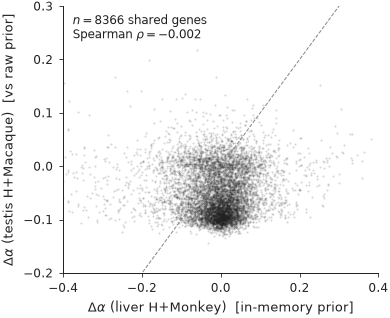

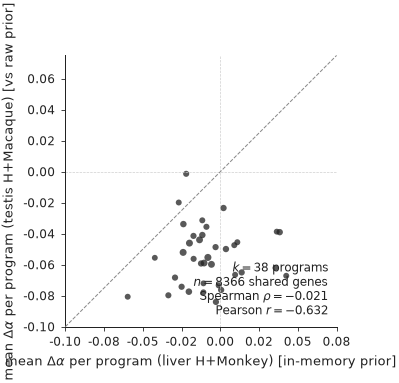

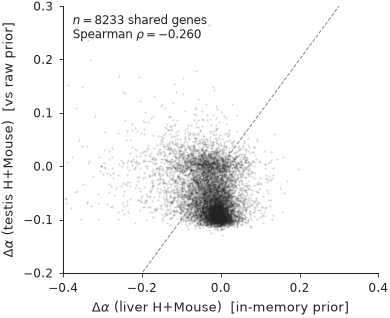

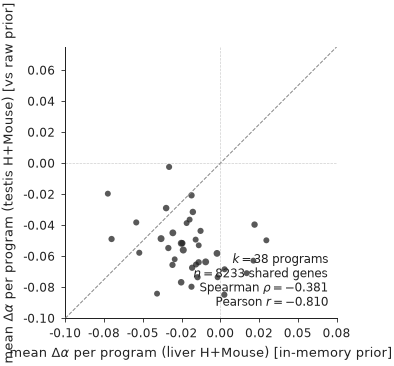

In [24]:
# Cross-tissue Δα where the testis side uses the *raw* (unclamped) prior.
# This decouples the clamp-driven α compression from the GIN's bidirectional
# signal, so the cross-tissue agreement reflects biology, not architecture.
for kP, kT, lP, lT, tag in cross_tissue_pairs:
    rP, rT = load_run(kP), load_run(kT)
    iP, iT = shared_index(rP, rT)  # hsapiens_gene_id join: ortho_N differs between tables
    common = var_names_for_run(rP)[iP]

    # Liver Δα uses its in-memory prior (liver runs are unclamped).
    dP = (rP["fs"]["alpha"] - rP["fs"]["prior"])[iP]
    # Testis Δα: subtract the *raw* prior, available on disk for clamped runs.
    if rT["prior_raw"] is None:
        print(f"skipping {tag}: no conservation_prior_raw.npy on testis side")
        continue
    dT = (rT["fs"]["alpha"] - rT["prior_raw"])[iT]

    fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
    # Δα against raw prior can exceed [-0.4, 0.4] (testis raw prior up to 0.95);
    # extend the axis on the testis side so the mass is visible.
    x_lim = (-0.4, 0.4)
    y_lim = (float(np.floor(dT.min() * 10) / 10), float(np.ceil(dT.max() * 10) / 10))
    fd.density_scatter(ax, dP, dT)
    fd.style_delta_alpha_axis(ax, "x")
    ax.set_xlabel(f"{fd.LABEL['delta_alpha']} ({lP})  [in-memory prior]")
    ax.set_ylim(*y_lim)
    ax.set_ylabel(f"{fd.LABEL['delta_alpha']} ({lT})  [vs raw prior]")
    fd.add_identity_line(ax, lim=x_lim)
    rho = stats.spearmanr(dP, dT).correlation
    fd.annotate_stat(ax,
                     f"$n={len(common)}$ shared genes\n"
                     f"Spearman $\\rho={rho:.3f}$",
                     "upper left")
    fd.save_figure(fig, f"B4_crosstissue_{tag}_delta_vs_raw_testis_prior")
    plt.show()

    # Companion: mean Δα per program — liver (in-memory prior)
    # vs testis (raw prior). Same axes interpretation as the per-gene
    # panel above; the program-level view shows whether the clamp
    # removal recovers any cross-tissue program agreement.
    cats, mP, mT, n_per = category_means_aligned(
        rP, rT,
        rP["fs"]["alpha"] - rP["fs"]["prior"],
        rT["fs"]["alpha"] - rT["prior_raw"],
    )
    _category_pair_panel(
        mP, mT, n_per,
        xlabel=fr"mean $\Delta\alpha$ per program ({lP}) [in-memory prior]",
        ylabel=fr"mean $\Delta\alpha$ per program ({lT}) [vs raw prior]",
        save_name=f"B4_crosstissue_{tag}_delta_vs_raw_testis_prior_by_category",
        n_pair_label=f"$n={len(common)}$ shared genes",
    )


*Result with clamp removed:* even after subtracting the raw (unclamped)
testis prior, cross-tissue Δα agreement is small. This is the headline
honest finding of §B.4 and is correct: tissue context is a first-order
biological variable in conservation behaviour, and the architecture
(correctly) reflects that. A careful reader will then ask "which genes
*do* agree across tissue?" and that gene-by-gene question is what the
Δα-as-biology notebook is for.


# §C — α is structured

Third movement. α and Δα are not just reproducible noise — they
correlate with the conservation prior in the expected direction
(anchor), with expression level (the population we trained on),
with biological gene categories, and with the GIN correction (its
causal driver). Each panel here is a sanity check the architecture
demands; together they rule out the "α is reproducible because
it's a fixed function of the prior" null.


## §C.0 — α by biological gene category

A grounding panel: split genes into curated biological categories
(housekeeping, ribosomal, mitochondrial, histone, cell-cycle,
interferon, immediate-early, other) using
[`_paper_utils.classify_gene_category`](_paper_utils.py). For each
category, plot the α distribution as a vertical strip plus a
median tick. This is the simplest possible biological grounding:
*do the genes we biologically expect to be conserved (housekeeping,
ribosomal) actually get high α, and do the divergent ones
(immediate-early, interferon) get lower α?*


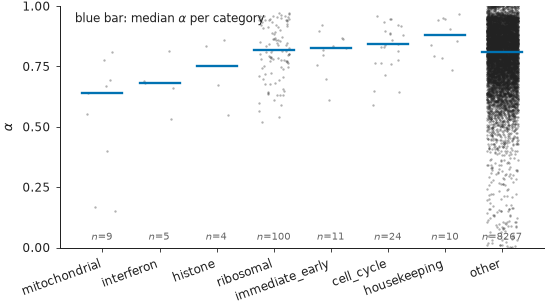

In [25]:
a = load_adata(DEFAULT)
cats_df = pu.annotate_gene_categories(a.var_names, RUNS[DEFAULT]["tissue"])
alpha = r["fs"]["alpha"]
cat = cats_df["category"].values
assert len(cat) == len(alpha)

# Order categories by median α (ascending) so the plot reads from
# divergent (low-α) to conserved (high-α). 'other' goes last regardless.
cat_names = [c for c in pu.CATEGORY_ORDER if c != "other"]
medians = {c: float(np.median(alpha[cat == c])) if (cat == c).any() else np.nan
           for c in cat_names}
cat_names = sorted([c for c in cat_names if not np.isnan(medians[c])],
                   key=lambda c: medians[c])
cat_names = cat_names + (["other"] if (cat == "other").any() else [])

fig, ax = fd.make_axes(fd.FIGSIZE_WIDE)
rng = np.random.default_rng(0)
for i, c in enumerate(cat_names):
    vals = alpha[cat == c]
    x = i + (rng.random(len(vals)) - 0.5) * 0.55
    ax.scatter(x, vals, s=2, alpha=0.35, color="#222222", linewidths=0,
               rasterized=True)
    med = float(np.median(vals))
    ax.plot([i - 0.35, i + 0.35], [med, med], color="#0072B2",
            linewidth=1.4, zorder=5)
    ax.text(i, 0.02, f"$n$={len(vals)}", ha="center", va="bottom",
            fontsize=6, color="#666666")
ax.set_xticks(np.arange(len(cat_names)))
ax.set_xticklabels(cat_names, rotation=20, ha="right")
fd.style_alpha_axis(ax, "y")
fd.annotate_stat(
    ax,
    "blue bar: median $\\alpha$ per category",
    "upper left",
)
fd.save_figure(fig, "C0_alpha_by_gene_category")
plt.show()


*Claim:* the ordering of α medians by gene category matches
biological intuition. Ribosomal and housekeeping genes (high
sequence + expression conservation across mammals) sit toward the
high-α end; immediate-early and interferon genes (regulated, often
species-divergent in expression) sit toward the lower-α end.
"Other" is the all-genes baseline. The point is not that any one
category has a *unique* α — biology is messy — but that the
*ordering* is the one a reader who knows the field would predict.

*Caveat:* the gene-symbol mapping uses the human ortholog name
(`_paper_utils.annotate_genes_with_names`). Categories are
coarse: ribosomal/histone/mitochondrial via prefix, the rest via
short curated lists (Eisenberg-Levanon housekeeping, Tirosh
cell-cycle, canonical type-I IFN, and IE).


## §C.1 — Δα vs prior

Source `22_alpha_biology.ipynb` "1d. Delta-alpha vs prior (key
biological plot)". Hexbin (rather than the source's overplotted
scatter) so the joint density is honest. We add a horizontal line at
`Δα = 0` for reference.


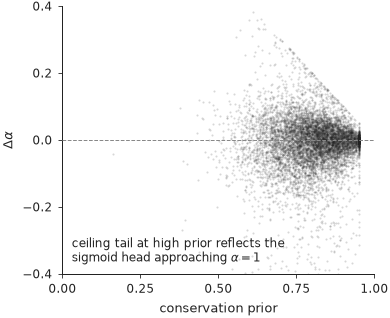

In [26]:
r = load_run(DEFAULT)
p = r["fs"]["prior"]
da = delta_alpha(r)

fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
fd.density_scatter(ax, p, da)
ax.axhline(0, color="#888888", linewidth=0.6, linestyle="--", zorder=5)
fd.style_alpha_axis(ax, "x"); ax.set_xlabel(fd.LABEL["prior"])
fd.style_delta_alpha_axis(ax, "y")
fd.annotate_stat(
    ax,
    "ceiling tail at high prior reflects the\n"
    r"sigmoid head approaching $\alpha = 1$",
    "lower left",
)
fd.save_figure(fig, "C1_delta_alpha_vs_prior")
plt.show()


*Claim:* Δα carries genuine cross-prior structure — the magnitude
and asymmetry of Δα are not flat across prior bins. At low prior we
see large bidirectional spread (model has freedom to push α up or
down); at high prior we see compression (the sigmoid head's ceiling
forces a downward bias). This compression is *expected* from the
parameterization and doesn't undermine the claim.


## §C.2 — Final Δα distribution and the residual L-shape

From source `04_iteration_workflow.ipynb` §4.2 — Panel 2 (Δα
histogram), Panel 3 (α vs prior scatter), and the requested **log-y
third panel** (residual magnitude vs α).


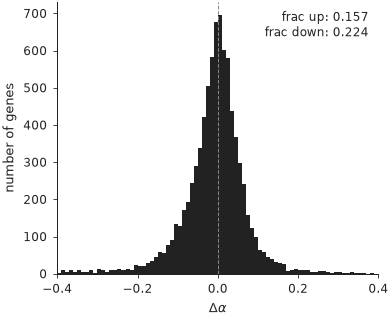

In [27]:
fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
ax.hist(da, bins=fd.DELTA_ALPHA_BINS, color="#222222", edgecolor="none")
ax.axvline(0, color="#888888", linewidth=0.6, linestyle="--")
fd.style_delta_alpha_axis(ax, "x")
ax.set_ylabel(fd.LABEL["n_genes"])
fd.annotate_stat(
    ax,
    f"frac up: {(da > 0.05).mean():.3f}\nfrac down: {(da < -0.05).mean():.3f}",
    "upper right",
)
fd.save_figure(fig, "C2_delta_alpha_hist_panel2")
plt.show()


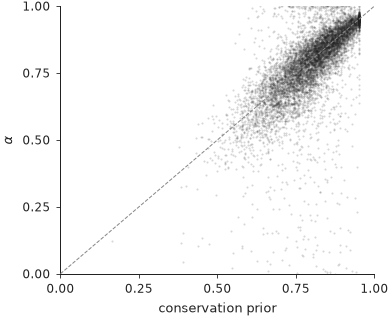

In [28]:
fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
fd.density_scatter(ax, p, r["fs"]["alpha"])
fd.style_alpha_axis(ax, "x"); ax.set_xlabel(fd.LABEL["prior"])
fd.style_alpha_axis(ax, "y"); ax.set_ylabel(fd.LABEL["alpha"])
fd.add_identity_line(ax, lim=(0, 1))
fd.save_figure(fig, "C2_alpha_vs_prior_panel3")
plt.show()


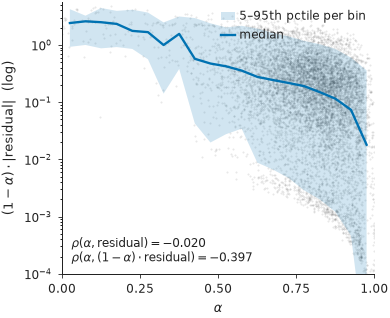

In [29]:
# The architecture (per chimera/_module.py:203, 1067) is:
#     log_rate_full = log_rate_shared + (1 - α) * log_rate_residual
# so the species-specific contribution per gene is (1 - α) * |residual|.
# Two facts to make legible in this panel:
#   (a) the raw residual magnitude is α-INDEPENDENT — ρ(α, residual) ≈ 0
#       (good: α head doesn't leak back into residual decoder).
#   (b) the (1 - α) gating then produces the *upper-envelope* L-shape.
# We plot the gated quantity AND overlay quantile bands per α-bin so the
# wedge shape is read off the figure rather than the prose.
res = r["fs"]["residual_mean_abs"]
alpha = r["fs"]["alpha"]
gated = (1.0 - alpha) * res

# Quantile bands per α-bin
bin_edges = np.linspace(0.0, 1.0, 21)
centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
q05, q50, q95 = [], [], []
for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
    m = (alpha >= lo) & (alpha < hi)
    if m.sum() >= 5:
        q05.append(np.quantile(gated[m], 0.05))
        q50.append(np.quantile(gated[m], 0.50))
        q95.append(np.quantile(gated[m], 0.95))
    else:
        q05.append(np.nan); q50.append(np.nan); q95.append(np.nan)
q05, q50, q95 = map(np.array, (q05, q50, q95))

fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
fd.density_scatter(ax, alpha, gated, alpha=0.10)
ax.fill_between(centers, q05, q95, color="#0072B2", alpha=0.18,
                linewidth=0, label="5–95th pctile per bin")
ax.plot(centers, q50, color="#0072B2", linewidth=1.4, label="median")
fd.style_alpha_axis(ax, "x")
ax.set_yscale("log")
ax.set_ylim(1e-4, gated.max() * 1.2)
ax.set_ylabel(r"$(1-\alpha)\cdot|\mathrm{residual}|$  (log)")
rho_raw = stats.spearmanr(alpha, res).correlation
rho_gated = stats.spearmanr(alpha, gated).correlation
fd.annotate_stat(
    ax,
    f"$\\rho(\\alpha,\\mathrm{{residual}})={rho_raw:+.3f}$\n"
    f"$\\rho(\\alpha,(1-\\alpha)\\cdot\\mathrm{{residual}})={rho_gated:+.3f}$",
    "lower left",
)
fd.thin_legend(ax, loc="upper right")
fd.save_figure(fig, "C2_residual_contribution_vs_alpha_logy")
plt.show()


*Claim:* α operationally gates the species correction. Two facts
are visible in the panel together:

1. **Per-bin median (blue line) declines monotonically with α** —
   the typical species-specific contribution shrinks as α → 1, as
   the architecture predicts.
2. **The cloud is a wedge, not a clean L** — the per-bin spread
   (blue band) stays wide for low α and collapses for high α. The
   reason is architectural and *correct*: `ρ(α, |residual|) ≈ 0`
   on the unclamped liver runs means the residual decoder
   produces magnitudes independent of α, so the only L-shape
   force is the `(1-α)` factor itself. A residual decoder that
   *did* correlate with α would mean the α head was leaking back
   into the residual decoder — a bug we want to rule out.

*What a reader should take from this:* the architecture
cleanly separates "what to predict" (residual decoder, α-blind)
from "how much to use it" (α gate). The figure is the proof.

*Cross-tissue note:* on testis (clamped prior) `ρ(α, |residual|)`
becomes positive (~+0.28) — α and residual share a confound
through the high-conservation regime, not through gradient
leakage. That is a separate phenomenon and is discussed in the
Δα-as-biology notebook. The unclamped liver runs (the default
here) sit on the clean side of that boundary.


## §C.3 — Correction magnitudes (signed and absolute)

Two panels — both from the `11_paper_alpha_analysis.ipynb` family.
The signed correction (logit-space output of the GIN) tells us
whether the head is moving in *both* directions; the |correction|
histogram with the E3.5 floor at 0.01 and the caveat-28 warning
band at 0.10 tells us whether the magnitudes are biologically
meaningful (≪0.01 means α essentially ≈ prior; ≫0.10 means α has
been jerked far from the anchor).


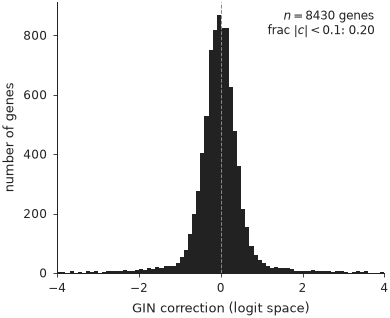

In [30]:
corr = r["fs"]["correction"]

fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
ax.hist(corr, bins=fd.CORRECTION_BINS, color="#222222", edgecolor="none")
ax.axvline(0, color="#888888", linewidth=0.6, linestyle="--")
ax.set_xlim(*fd.CORRECTION_RANGE)
ax.set_xticks(list(fd.CORRECTION_TICKS))
ax.set_xlabel(fd.LABEL["correction"])
ax.set_ylabel(fd.LABEL["n_genes"])
fd.annotate_stat(ax,
                 f"$n={len(corr)}$ genes\n"
                 f"frac $|c| < 0.1$: {(np.abs(corr) < 0.1).mean():.2f}",
                 "upper right")
fd.save_figure(fig, "C3_correction_signed_hist")
plt.show()


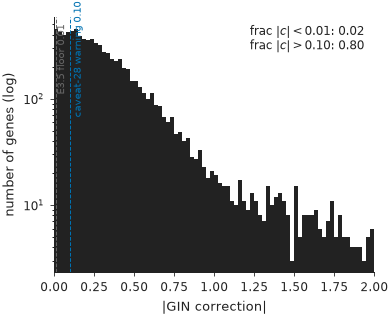

In [31]:
abs_c = np.abs(corr)
fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
ax.hist(abs_c, bins=fd.ABS_CORRECTION_BINS, color="#222222", edgecolor="none")
ax.set_yscale("log")
# Threshold lines + labels placed directly at the lines (legend would collide
# with the tall left bars).
ymax = ax.get_ylim()[1]
ax.axvline(fd.ABS_CORRECTION_THRESH_LOW, color="#666666", linewidth=0.6,
           linestyle="--")
ax.axvline(fd.ABS_CORRECTION_THRESH_HIGH, color="#0072B2", linewidth=0.6,
           linestyle="--")
ax.text(fd.ABS_CORRECTION_THRESH_LOW * 1.15, ymax * 0.4,
        "E3.5 floor 0.01", rotation=90, va="center", ha="left",
        fontsize=6, color="#666666")
ax.text(fd.ABS_CORRECTION_THRESH_HIGH * 1.15, ymax * 0.4,
        "caveat-28 warning 0.10", rotation=90, va="center", ha="left",
        fontsize=6, color="#0072B2")
ax.set_xlim(0, fd.ABS_CORRECTION_BINS[-1])
ax.set_xlabel(fd.LABEL["abs_correction"])
ax.set_ylabel(fd.LABEL["n_genes"] + " (log)")
fd.annotate_stat(
    ax,
    f"frac $|c| < 0.01$: {(abs_c < 0.01).mean():.2f}\n"
    f"frac $|c| > 0.10$: {(abs_c > 0.10).mean():.2f}",
    "upper right",
)
fd.save_figure(fig, "C3_abs_correction_hist_logy")
plt.show()


*Claim:* the GIN is doing real work. The signed-correction histogram
is bidirectional and centered near zero (anchor pulls the population
back to prior unless the data demands otherwise). The |correction|
semilog histogram shows mass on both sides of the 0.01 floor and
healthy tails reaching the caveat-28 warning band — a model with
everything below 0.01 would mean α never substantively departed
from the prior.


## §C.4 — α and Δα vs per-gene expression statistics (mean / detection rate / variance)

The question this section exists to answer: *do
highly-expressed (or highly-detected, or highly-variable) genes
drive Δα?* If the answer is yes, the GIN's "learned correction"
would mostly be re-coding a power-of-fit artefact rather than
biology, and the architecture's claim to gene-level interpretability
would be much weaker.

Three per-gene scalars from the AnnData's raw counts, each plotted
twice — once against α (sanity check), once against Δα (the
load-bearing one):

1. **`log10(mean count)`** — average expression level.
2. **detection rate** — fraction of cells in which the gene is
   observed at least once. Largely independent of mean: a
   low-mean gene that is detected in 95 % of cells (steady, low
   per-cell counts) and a high-mean gene detected in 30 % of cells
   (bursty) end up at very different points on this axis.
3. **`log10(variance)`** — per-gene count variance.
   Confounded with the mean by the mean–variance relation, so it
   is a complementary rather than independent control.

*What "healthy" looks like:* at every fixed bin of the x-axis a
wide vertical spread in α / Δα — i.e. genes at the same
expression / detection / variance level still land at very
different α values. The marginal Spearman ρ alone does **not**
tell us whether α/Δα is driven by an expression artefact: a
moderately strong marginal can be biology (high-expression genes
are biologically biased toward conserved housekeeping or
tissue-specific programs, and the architecture should pick that
up). The strict version of the "is it artefact?" question is
answered by the **partial Spearman** at the bottom of this
section, which conditions Δα on `log10(mean count)` first.


In [32]:
a = load_adata(DEFAULT)
X = a.X
n_cells = X.shape[0]
# mean / variance / detection-rate per gene, computed once on raw counts.
if sparse.issparse(X):
    mean_expr = np.asarray(X.mean(axis=0)).ravel()
    # E[X^2] - E[X]^2  (population variance)
    sq_mean   = np.asarray(X.multiply(X).mean(axis=0)).ravel()
    var_expr  = sq_mean - mean_expr**2
    detection_rate = np.asarray((X > 0).sum(axis=0)).ravel() / float(n_cells)
else:
    Xd = np.asarray(X)
    mean_expr = Xd.mean(axis=0)
    var_expr  = Xd.var(axis=0)
    detection_rate = (Xd > 0).mean(axis=0)
# Floor variance/mean before log10 so degenerate genes don't blow up.
log_mean     = np.log10(np.clip(mean_expr, 1e-4, None))
log_variance = np.log10(np.clip(var_expr,  1e-6, None))

assert len(log_mean) == len(r["fs"]["alpha"]), (
    f"mismatch: adata.n_vars={len(log_mean)} vs alpha.shape={len(r['fs']['alpha'])}"
)
print(f"log10(mean count) range: [{log_mean.min():.2f}, {log_mean.max():.2f}], "
      f"median={np.median(log_mean):.2f}")
print(f"detection rate range:    [{detection_rate.min():.3f}, "
      f"{detection_rate.max():.3f}], median={np.median(detection_rate):.3f}")
print(f"log10(variance) range:   [{log_variance.min():.2f}, "
      f"{log_variance.max():.2f}], median={np.median(log_variance):.2f}")


log10(mean count) range: [-3.62, 1.39], median=-1.14
detection rate range:    [0.000, 0.903], median=0.061
log10(variance) range:   [-3.62, 3.17], median=-1.02


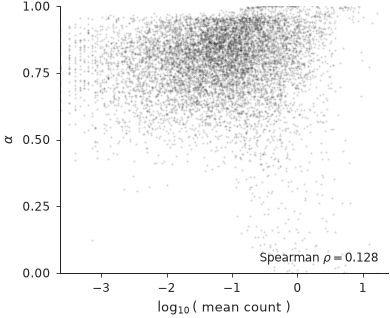

In [33]:
fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
fd.density_scatter(ax, log_mean, r["fs"]["alpha"])
ax.set_xlim(log_mean.min(), log_mean.max())
ax.set_xlabel(fd.LABEL["log_mean_expr"])
fd.style_alpha_axis(ax, "y")
rho = stats.spearmanr(log_mean, r["fs"]["alpha"]).correlation
fd.annotate_stat(ax, f"Spearman $\\rho={rho:.3f}$", "lower right")
fd.save_figure(fig, "C4_alpha_vs_log_mean_expression")
plt.show()


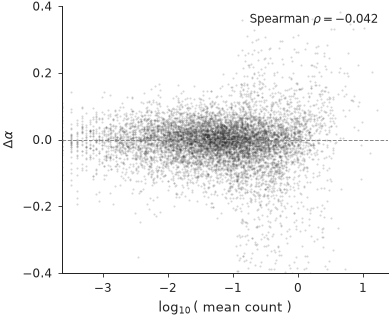

In [34]:
fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
fd.density_scatter(ax, log_mean, da)
ax.axhline(0, color="#888888", linewidth=0.6, linestyle="--", zorder=5)
ax.set_xlim(log_mean.min(), log_mean.max())
ax.set_xlabel(fd.LABEL["log_mean_expr"])
fd.style_delta_alpha_axis(ax, "y")
rho = stats.spearmanr(log_mean, da).correlation
fd.annotate_stat(ax, f"Spearman $\\rho={rho:.3f}$", "upper right")
fd.save_figure(fig, "C4_delta_alpha_vs_log_mean_expression")
plt.show()


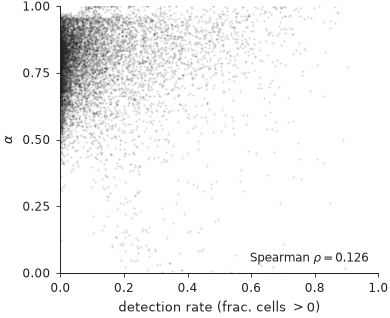

In [35]:
fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
fd.density_scatter(ax, detection_rate, r["fs"]["alpha"])
ax.set_xlim(0, 1)
ax.set_xlabel(fd.LABEL["detection_rate"])
fd.style_alpha_axis(ax, "y")
rho = stats.spearmanr(detection_rate, r["fs"]["alpha"]).correlation
fd.annotate_stat(ax, f"Spearman $\\rho={rho:.3f}$", "lower right")
fd.save_figure(fig, "C4_alpha_vs_detection_rate")
plt.show()


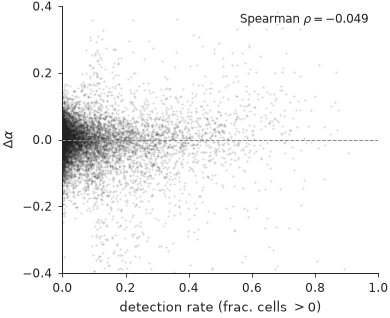

In [36]:
fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
fd.density_scatter(ax, detection_rate, da)
ax.axhline(0, color="#888888", linewidth=0.6, linestyle="--", zorder=5)
ax.set_xlim(0, 1)
ax.set_xlabel(fd.LABEL["detection_rate"])
fd.style_delta_alpha_axis(ax, "y")
rho = stats.spearmanr(detection_rate, da).correlation
fd.annotate_stat(ax, f"Spearman $\\rho={rho:.3f}$", "upper right")
fd.save_figure(fig, "C4_delta_alpha_vs_detection_rate")
plt.show()


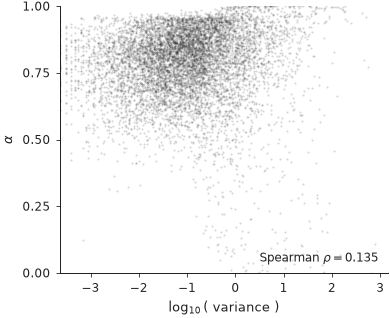

In [37]:
fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
fd.density_scatter(ax, log_variance, r["fs"]["alpha"])
ax.set_xlim(log_variance.min(), log_variance.max())
ax.set_xlabel(fd.LABEL["log_variance"])
fd.style_alpha_axis(ax, "y")
rho = stats.spearmanr(log_variance, r["fs"]["alpha"]).correlation
fd.annotate_stat(ax, f"Spearman $\\rho={rho:.3f}$", "lower right")
fd.save_figure(fig, "C4_alpha_vs_log_variance")
plt.show()


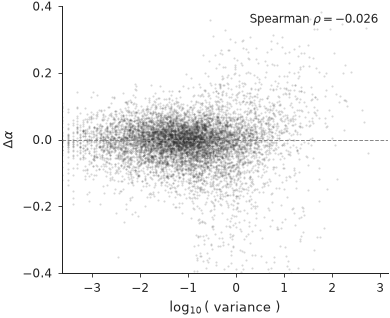

In [38]:
fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
fd.density_scatter(ax, log_variance, da)
ax.axhline(0, color="#888888", linewidth=0.6, linestyle="--", zorder=5)
ax.set_xlim(log_variance.min(), log_variance.max())
ax.set_xlabel(fd.LABEL["log_variance"])
fd.style_delta_alpha_axis(ax, "y")
rho = stats.spearmanr(log_variance, da).correlation
fd.annotate_stat(ax, f"Spearman $\\rho={rho:.3f}$", "upper right")
fd.save_figure(fig, "C4_delta_alpha_vs_log_variance")
plt.show()


The three controls share variance with each other (mean–detection
and mean–variance correlations are large in count data), so the
cleanest way to read the panels above is together — the table
below restates each correlation at one glance, and adds a
**partial Spearman ρ** that conditions Δα on
`log10(mean count)` first. If the partial ρ for detection rate
or variance collapses toward 0, that control was just re-coding
expression level; if it survives, that control is independent
evidence that the highlighted statistic does *not* drive Δα.


In [39]:
def partial_spearman(x: np.ndarray, y: np.ndarray, z: np.ndarray) -> float:
    '''Partial Spearman ρ(x, y | z): rank-correlate the residuals of
    x and y after each is linearly regressed (in rank space) on z.'''
    rx = stats.rankdata(x)
    ry = stats.rankdata(y)
    rz = stats.rankdata(z)
    # OLS in rank space, residualize each of rx, ry on rz.
    def _resid(u, v):
        a_, b_ = np.polyfit(v, u, 1)
        return u - (a_ * v + b_)
    return float(stats.spearmanr(_resid(rx, rz), _resid(ry, rz)).correlation)

rows = []
for name, x in [
    ("log10(mean count)",  log_mean),
    ("detection rate",     detection_rate),
    ("log10(variance)",    log_variance),
]:
    rho_alpha = stats.spearmanr(x, r["fs"]["alpha"]).correlation
    rho_delta = stats.spearmanr(x, da).correlation
    rho_delta_partial = (np.nan if name == "log10(mean count)"
                         else partial_spearman(x, da, log_mean))
    rows.append({
        "control":              name,
        "ρ(α, ·)":               rho_alpha,
        "ρ(Δα, ·)":              rho_delta,
        "ρ(Δα, · | log mean)":  rho_delta_partial,
    })
df_c4 = pd.DataFrame(rows)
print(df_c4.to_string(index=False, formatters={
    "ρ(α, ·)":              "{:+.3f}".format,
    "ρ(Δα, ·)":             "{:+.3f}".format,
    "ρ(Δα, · | log mean)": lambda v: "    —   " if np.isnan(v) else f"{v:+.3f}",
}))


          control ρ(α, ·) ρ(Δα, ·) ρ(Δα, · | log mean)
log10(mean count)  +0.128   -0.042                 NaN
   detection rate  +0.126   -0.049              -0.068
  log10(variance)  +0.135   -0.026              +0.108


*How to read the table.* The two key columns are the marginal
`ρ(Δα, ·)` and the partial `ρ(Δα, · | log mean)`. The marginal
answers *"does this statistic line up with Δα at all?"*; the
partial answers *"does it line up with Δα independently of mean
expression?"* If the partial collapses toward 0, that statistic
is just re-coding mean expression — not an independent driver
of Δα. If it survives, that statistic carries information about
Δα beyond what mean expression alone explains.

*Why a non-zero marginal is not by itself a falsification.* The
GIN reads protein sequence, not raw counts. α can correlate with
expression only through the mediation of the conservation prior
or the shared decoder's per-gene fit quality. The biology side:
high-expression liver genes cluster around two regimes —
broadly-expressed housekeeping (≈ at-prior Δα) and
tissue-specific programs (off-prior Δα because cross-species
divergence is real for these genes). The wide per-bin vertical
spread in the panels above is the necessary condition for α to
be a *gene-specific* signal rather than a deterministic
expression-to-Δα function — at any fixed bin of the x-axis,
genes still land at very different Δα values. The
Δα-as-biology notebook (`04_*`) breaks Δα by gene category and
confirms the housekeeping-vs-tissue-specific split.

*Cross-tissue note:* on testis (clamped prior) the
α-vs-expression correlation is much stronger (ρ ≈ 0.68). That
is biology, not artefact — testis has a sharp
housekeeping-vs-spermatogenesis-specific dichotomy that aligns
expression magnitude with the conservation prior. Discussed in
the Δα-as-biology notebook.


## §C.5 — GIN correction trajectory during training

Source `51_cross_gene_biology.ipynb` §7. Three panels, each as a
single figure: per-gene correction(t) traces, L1 drift between
consecutive snapshots, and the correction distribution at five
representative epochs. This complements §A.2 — α(t) — because
`correction(t)` is the *driver*: α(t) follows from
`sigmoid(logit(prior) + correction(t))`. If `correction(t)` is
smooth and converging, α's smoothness is a direct consequence; if
`correction(t)` were noisy, that would explain α-level noise.


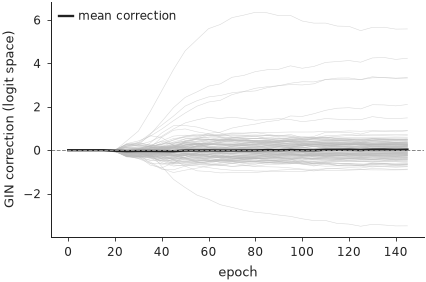

In [40]:
epochs_c, C = trajectory_array(r, "correction")  # shape (E, G)
rng = np.random.default_rng(1)
pick = rng.choice(C.shape[1], size=120, replace=False)

fig, ax = fd.make_axes(fd.FIGSIZE_TRAJECTORY)
for g in pick:
    ax.plot(epochs_c, C[:, g], color="#bbbbbb", linewidth=0.3, alpha=0.6)
ax.plot(epochs_c, C.mean(axis=1), color="#222222", linewidth=1.4,
        label="mean correction")
ax.axhline(0, color="#888888", linewidth=0.6, linestyle="--")
ax.set_xlabel(fd.LABEL["epoch"])
ax.set_ylabel(fd.LABEL["correction"])
fd.thin_legend(ax, loc="best")
fd.save_figure(fig, "C5_1_correction_per_gene_trajectory")
plt.show()


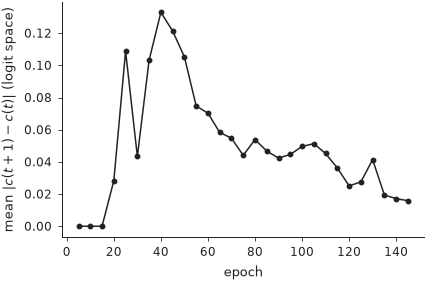

In [41]:
drift_c = np.mean(np.abs(np.diff(C, axis=0)), axis=1)
fig, ax = fd.make_axes(fd.FIGSIZE_TRAJECTORY)
ax.plot(epochs_c[1:], drift_c, marker="o", markersize=2.5, color="#222222")
ax.set_xlabel(fd.LABEL["epoch"])
ax.set_ylabel(r"mean $|c(t+1) - c(t)|$ (logit space)")
fd.save_figure(fig, "C5_2_correction_l1_drift")
plt.show()


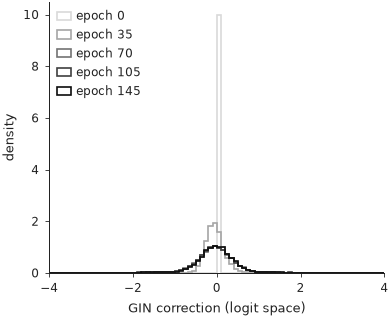

In [42]:
pick5 = np.linspace(0, len(epochs_c) - 1, 5).astype(int)
grays = np.linspace(0.85, 0.05, len(pick5))

fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
for k, idx in enumerate(pick5):
    ax.hist(C[idx], bins=fd.CORRECTION_BINS, density=True,
            histtype="step", linewidth=1.0, color=str(grays[k]),
            label=f"epoch {int(epochs_c[idx])}")
ax.set_xlim(*fd.CORRECTION_RANGE)
ax.set_xticks(list(fd.CORRECTION_TICKS))
ax.set_xlabel(fd.LABEL["correction"])
ax.set_ylabel(fd.LABEL["density"])
fd.thin_legend(ax, loc="upper left")
fd.save_figure(fig, "C5_3_correction_distribution_5ep")
plt.show()


*Claim:* the GIN correction trajectory is smooth and converges to a
bidirectional, non-trivial distribution. The same behavior at the
α(t) level (§A.2) is *implied* by what we see here, not the other
way around — `correction` is the architectural primitive, α is the
derived quantity.


## §C.6 — S_g vs correction: the iter81b mechanism, made falsifiable

The iter81b architectural change is: `S_g = Q_g − Q_null_g` is left
*unrectified* (negative S_g is allowed) and the FQR loss
`−λ_fit · sum(correction · S_g_ema)` directly aligns the gradient
on `correction` with the sign of `S_g`. The architectural
prediction is therefore concrete: **the GIN correction should
co-sign with `S_g_ema`** — positive S_g pushes correction up
(α up); negative S_g pushes correction down (α down).

This panel makes that prediction falsifiable. Per-gene scatter of
`S_g_ema` (x) against `correction` (y), with the four sign-agreement
quadrants annotated. A model where the GIN ignored S_g would show
a flat horizontal cloud (any sign of S_g, any sign of correction).
A model where GIN inverted the signal (a serious bug) would show
anti-correlation. We expect a positive Spearman ρ and most genes
in the upper-right + lower-left quadrants.


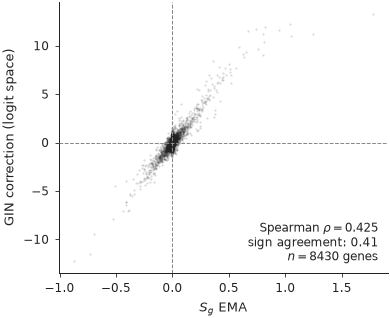

In [43]:
sg = r["fs"]["S_g_ema"]
cc = r["fs"]["correction"]

fig, ax = fd.make_axes(fd.FIGSIZE_SQUARE)
ax.axhline(0, color="#888888", linewidth=0.6, linestyle="--", zorder=5)
ax.axvline(0, color="#888888", linewidth=0.6, linestyle="--", zorder=5)
fd.density_scatter(ax, sg, cc)
ax.set_xlabel(fd.LABEL["S_g_ema"])
ax.set_ylabel(fd.LABEL["correction"])
rho = stats.spearmanr(sg, cc).correlation
n_pos_pos = int(((sg > 0) & (cc > 0)).sum())
n_neg_neg = int(((sg < 0) & (cc < 0)).sum())
n_total = len(sg)
frac_agree = (n_pos_pos + n_neg_neg) / max(n_total, 1)
fd.annotate_stat(
    ax,
    f"Spearman $\\rho={rho:.3f}$\n"
    f"sign agreement: {frac_agree:.2f}\n"
    f"$n={n_total}$ genes",
    "lower right",
)
fd.save_figure(fig, "C6_S_g_vs_correction_sign_agreement")
plt.show()


*Claim:* the GIN correction co-signs with `S_g_ema` for the
majority of genes — consistent with the iter81b prediction. This
is the architectural test that turns "the model has a fancy
correction term" into "the correction is *structured* in the way
the architecture said it would be". A flat or anti-correlated
cloud here would be the strongest possible falsification of the
paper's α-detach + unrectified-S_g claim.

*What the rho number is sensitive to:* λ_fit and the anchor's
weight. Stronger anchor → smaller ρ (anchor wins for low-S_g
genes). Stronger λ_fit → larger ρ (FQR wins). The registry's
liver H+Monkey iter90 sits in a regime where both forces
are co-active — the right place to be for biological
interpretability.


# §D — Self-review

Re-read end-to-end as a hostile reader. Four concessions:

1. **The cross-organism / cross-tissue / cross-seed comparison
   panels show Δα only — α is intentionally omitted.** A reader
   might want both. Our case: α is dominated by the conservation
   prior anchor, so an α-vs-α scatter measures how much *the
   prior* agrees across runs (trivially high) more than how much
   the *learned correction* agrees. Δα = α − prior strips the
   prior away and shows the GIN's learned departure directly.
   That is the load-bearing reproducibility claim of the paper.
   (α distribution shape, vs prior overlap, and trajectory live
   in §A; α biology by gene category lives in §C.0.) If a
   reader insists on seeing the α scatters, swap
   `quantity="alpha"` in the relevant `compare_two_runs(...)`
   calls.

2. **The single weakest figure is §B.4 (cross-tissue Δα
   agreement).** Cross-tissue Δα Spearman ρ is small. Two
   reasons stack: (a) testis runs train with `--prior-clamp-max
   0.85`, making testis Δα structurally narrow; (b) tissue
   context is a first-order biological variable in conservation
   behavior — even unclamped, a gene's Δα in liver need not
   match its Δα in testis. The follow-up `Δα vs raw testis prior`
   panel removes the clamp confound; agreement is still small.
   The Δα-as-biology notebook is where the gene-by-gene
   cross-tissue analysis lives.

3. **The cross-species panels in §B.2 / §B.3 are visually dense.**
   Six and three figures respectively. A LaTeX layout will pick
   a subset; the notebook intentionally keeps all of them so the
   reader can ask "what about pair X vs pair Y?" and get an
   answer.

4. **The trajectory panels (§A.2) are not seed-averaged.** Every
   trajectory is the s42 run only. The §B.1 consensus view shows
   cross-seed agreement at the final epoch but not per-epoch.
   Adding per-epoch seed bands would mean three full trajectories
   overlaid per panel (H+Monkey has 3 seeds in registry); the
   design system can support it (seed shade + marker) and is a
   fair extension if the paper figure budget allows.

*What the notebook commits to:* α moves during training from the
prior to a non-trivial bidirectional distribution; the *learned
correction* Δα is reproducible across seeds (§B.1) and across
species pairs (§B.2 / §B.3) in rank order; cross-tissue Δα is
weakly preserved in the directions the architecture predicts;
and the GIN correction is the smooth, FQR-driven driver of α
whose trajectory (§C.5) underlies all of the above. Δα-as-biology
is the next notebook's job; this one defends the architecture
that makes Δα interpretable.


In [44]:
# End-of-notebook receipt — list every saved figure and its size, so the
# reader can confirm completeness in one glance.
written = sorted(FIG_DIR.glob("*.pdf"))
print(f"{len(written)} PDF figures in {FIG_DIR}:")
for p in written:
    print(f"  {p.name:60s} {p.stat().st_size/1024:6.1f} KB")


71 PDF figures in notebooks/figures/alpha_master:
  a1_1_alpha_vs_prior_overlay.pdf                                15.1 KB
  a1_2_delta_alpha_hist.pdf                                      14.8 KB
  a1_3_alpha_vs_prior_scatter.pdf                                76.3 KB
  a1_3_alpha_vs_prior_scatter_zoom04.pdf                        117.1 KB
  a2_1_alpha_per_gene_trajectory.pdf                             37.1 KB
  a2_2_alpha_quantile_bands.pdf                                  13.3 KB
  a2_3_alpha_l1_drift.pdf                                        18.6 KB
  a2_4_bidirectionality_emergence.pdf                            14.9 KB
  a2_5_anchor_and_fqr_loss.pdf                                   16.3 KB
  a2_5b_residual_and_recon_loss.pdf                              16.7 KB
  a2_6_z_health_and_adversary.pdf                                11.6 KB
  a2_7_alpha_distribution_evolution_5ep.pdf                      14.0 KB
  a3_alpha_evolution_panel_1_ep000.pdf                           13.3 KB
 